In [ ]:
!pip install cobra pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 27.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 80.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 78.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [cobra]


In [ ]:
import cobra
import pandas as pd

model = cobra.io.read_sbml_model("/content/iML1515 (2).xml.gz")

print("Назва моделі:", model.id)
print("Кількість генів:", len(model.genes))
print("Кількість реакцій:", len(model.reactions))
print("Кількість метаболітів:", len(model.metabolites))

Назва моделі: iML1515
Кількість генів: 1516
Кількість реакцій: 2712
Кількість метаболітів: 1877


In [ ]:
# Створюємо окрему копію початкової моделі
h2_model = model.copy()

# Налаштовуємо анаеробні умови
h2_model.reactions.get_by_id("EX_o2_e").bounds = (0, 1000)

# Налаштовуємо реакції, пов'язані з утворенням водню
h2_model.reactions.get_by_id("FHL").bounds = (0, 1000)
h2_model.reactions.get_by_id("PPTHpp").bounds = (0, 0)

# Обмежуємо поглинання глюкози
h2_model.reactions.get_by_id("EX_glc__D_e").bounds = (-10, 1000)

# Визначаємо реакцію біомаси
biomass_id = "BIOMASS_Ec_iML1515_core_75p37M"

# Спочатку обчислюємо максимальний ріст
h2_model.objective = biomass_id
h2_model.objective_direction = "max"

growth_solution = h2_model.optimize()

print("Статус розрахунку росту:", growth_solution.status)
print("Максимальний ріст:", growth_solution.objective_value)

# Встановлюємо мінімальний ріст на рівні 10% від максимального
min_growth = 0.1 * growth_solution.objective_value
h2_model.reactions.get_by_id(biomass_id).lower_bound = min_growth

# Максимізуємо експорт водню
h2_model.objective = "EX_h2_e"
h2_model.objective_direction = "max"

h2_solution = h2_model.optimize()

print("\nСтатус розрахунку водню:", h2_solution.status)
print("Мінімальний ріст:", min_growth)
print("Формування H2:", h2_solution.fluxes["EX_h2_e"])

Статус розрахунку росту: optimal
Максимальний ріст: 0.19617163820882896

Статус розрахунку водню: optimal
Мінімальний ріст: 0.019617163820882896
Формування H2: 87.8602264435134


## Аналіз пентозофосфатного шляху та балансу NADPH

На цьому етапі досліджується активність реакцій пентозофосфатного шляху та їхній внесок у метаболізм NADPH. Аналіз дає змогу оцінити роль цього шляху в забезпеченні клітини відновними еквівалентами.

In [ ]:
# Реакції пентозофосфатного шляху
ppp_reactions = [
    "G6PDH2r",
    "PGL",
    "GND",
    "RPI",
    "RPE",
    "TKT1",
    "TKT2",
    "TALA"
]

for rxn_id in ppp_reactions:
    rxn = h2_model.reactions.get_by_id(rxn_id)
    print(rxn_id, ":", h2_solution.fluxes[rxn_id])

G6PDH2r : 36.29169464974469
PGL : 36.291694649744684
GND : 36.29169464974469
RPI : -12.111672718522678
RPE : 24.179241089633326
TKT1 : 12.093354407118243
TKT2 : 12.085886682515083
TALA : 12.093354407118243


In [ ]:
# Аналіз реакцій, які беруть участь
# у балансі NADPH

nadph = h2_model.metabolites.get_by_id("nadph_c")

for reaction in h2_model.reactions:
    coefficient = reaction.metabolites.get(nadph, 0)

    if coefficient != 0:
        flux = h2_solution.fluxes[reaction.id]
        contribution = coefficient * flux

        if abs(contribution) > 0.001:
            role = "Утворення NADPH" if contribution > 0 else "Споживання NADPH"

            print(
                reaction.id,
                "| Потік:", round(flux, 5),
                "| Внесок:", round(contribution, 5),
                "|", role
            )

SHK3Dr | Потік: 0.00748 | Внесок: -0.00748 | Споживання NADPH
G5SD | Потік: 0.00434 | Внесок: -0.00434 | Споживання NADPH
ICDHyr | Потік: 0.02109 | Внесок: 0.02109 | Утворення NADPH
KARA1 | Потік: -0.01715 | Внесок: -0.01715 | Споживання NADPH
KARA2 | Потік: 0.0057 | Внесок: -0.0057 | Споживання NADPH
AGPR | Потік: -0.0058 | Внесок: -0.0058 | Споживання NADPH
DHDPRy | Потік: 0.00728 | Внесок: -0.00728 | Споживання NADPH
TRDR | Потік: 0.00694 | Внесок: -0.00694 | Споживання NADPH
G3PD2 | Потік: -0.00273 | Внесок: -0.00273 | Споживання NADPH
P5CR | Потік: 0.00434 | Внесок: -0.00434 | Споживання NADPH
ASAD | Потік: -0.02097 | Внесок: -0.02097 | Споживання NADPH
SULR | Потік: 0.00485 | Внесок: -0.01456 | Споживання NADPH
GND | Потік: 36.29169 | Внесок: 36.29169 | Утворення NADPH
G6PDH2r | Потік: 36.29169 | Внесок: 36.29169 | Утворення NADPH
HSDy | Потік: -0.0137 | Внесок: -0.0137 | Споживання NADPH
THD2pp | Потік: 7.83256 | Внесок: 7.83256 | Утворення NADPH
MTHFD | Потік: 0.01944 | Внесок:

In [ ]:
tests = {
    "Контроль": [],
    "G6PDH2r вимкнена": ["G6PDH2r"],
    "GND вимкнена": ["GND"],
    "Обидві вимкнені": ["G6PDH2r", "GND"]
}

for name, reactions in tests.items():
    test_model = h2_model.copy()

    for rxn_id in reactions:
        test_model.reactions.get_by_id(rxn_id).bounds = (0, 0)

    solution = test_model.optimize()

    if solution.status == "optimal":
        print(
            name,
            "| H2:", round(solution.fluxes["EX_h2_e"], 5),
            "| Ріст:", round(solution.fluxes[biomass_id], 5)
        )
    else:
        print(name, "| Статус:", solution.status)

Контроль | H2: 87.86023 | Ріст: 0.01962
G6PDH2r вимкнена | H2: 67.23785 | Ріст: 0.01962
GND вимкнена | H2: 67.23785 | Ріст: 0.01962
Обидві вимкнені | H2: 67.23785 | Ріст: 0.01962


In [ ]:
for name, reactions in tests.items():
    test_model = h2_model.copy()

    for rxn_id in reactions:
        test_model.reactions.get_by_id(rxn_id).bounds = (0, 0)

    solution = test_model.optimize()

    if solution.status == "optimal":
        print(
            name,
            "| H2:", round(solution.fluxes["EX_h2_e"], 5),
            "| FLDR2:", round(solution.fluxes["FLDR2"], 5),
            "| POR5:", round(solution.fluxes["POR5"], 5)
        )

Контроль | H2: 87.86023 | FLDR2: 80.17498 | POR5: -80.17493
G6PDH2r вимкнена | H2: 67.23785 | FLDR2: 40.51373 | POR5: -40.51368
GND вимкнена | H2: 67.23785 | FLDR2: 40.51373 | POR5: -40.51368
Обидві вимкнені | H2: 67.23785 | FLDR2: 40.51373 | POR5: -40.51368


In [ ]:
import pandas as pd

glucose_levels = [5, 10, 15, 20]
results = []

for glucose in glucose_levels:

    # Створюємо окрему копію моделі
    test_model = h2_model.copy()

    # Змінюємо обмеження поглинання глюкози
    test_model.reactions.get_by_id("EX_glc__D_e").bounds = (
        -glucose, 1000
    )

    # Максимізуємо утворення водню
    test_model.objective = "EX_h2_e"
    test_model.objective_direction = "max"

    solution = test_model.optimize()

    if solution.status == "optimal":

        h2 = solution.fluxes["EX_h2_e"]
        glucose_uptake = -solution.fluxes["EX_glc__D_e"]
        biomass = solution.fluxes[biomass_id]

        results.append({
            "Глюкоза": glucose,
            "Поглинання глюкози": glucose_uptake,
            "Утворення H2": h2,
            "H2 / глюкоза": h2 / glucose_uptake,
            "Ріст": biomass
        })

    else:
        print("Глюкоза:", glucose, "| Статус:", solution.status)

# Створюємо таблицю результатів
results_df = pd.DataFrame(results)

display(results_df.round(5))

,Глюкоза,Поглинання глюкози,Утворення H2,H2 / глюкоза,Ріст
0,5,5.0,35.00441,7.00088,0.01962
1,10,10.0,87.86023,8.78602,0.01962
2,15,15.0,138.76932,9.25129,0.01962
3,20,20.0,189.67841,9.48392,0.01962


In [ ]:
# Створюємо модель для перевірки при поглинанні глюкози 20
carbon_model = h2_model.copy()

carbon_model.reactions.get_by_id("EX_glc__D_e").bounds = (-20, 1000)
carbon_model.objective = "EX_h2_e"
carbon_model.objective_direction = "max"

carbon_solution = carbon_model.optimize()

# Перевіряємо основні продукти обміну
exchange_ids = [
    "EX_glc__D_e",
    "EX_h2_e",
    "EX_co2_e",
    "EX_ac_e",
    "EX_for_e",
    "EX_etoh_e",
    "EX_succ_e",
    "EX_lac__D_e"
]

for rxn_id in exchange_ids:
    if rxn_id in carbon_model.reactions:
        print(
            rxn_id,
            round(carbon_solution.fluxes[rxn_id], 5)
        )

EX_glc__D_e -20.0
EX_h2_e 189.67841
EX_co2_e 94.87784
EX_ac_e 12.14537
EX_for_e 0.0
EX_etoh_e 0.0
EX_succ_e 0.00655
EX_lac__D_e 0.0


In [ ]:
key_reactions = [
    "PFL",
    "FHL",
    "POR5",
    "FLDR2",
    "G6PDH2r",
    "GND",
    "H2tpp",
    "H2tex",
    "EX_h2_e"
]

print("Потоки основних реакцій при поглинанні глюкози 20:\n")

for rxn_id in key_reactions:
    flux = carbon_solution.fluxes[rxn_id]
    print(f"{rxn_id}: {flux:.5f}")

Потоки основних реакцій при поглинанні глюкози 20:

PFL: 189.67836
FHL: 189.67841
POR5: -177.44766
FLDR2: 177.44770
G6PDH2r: 82.65533
GND: 82.65533
H2tpp: -189.67841
H2tex: -189.67841
EX_h2_e: 189.67841


In [ ]:
metabolites_to_check = [
    "pyr_c",
    "for_c",
    "accoa_c",
    "flxso_c",
    "flxr_c",
    "nadph_c"
]

for met_id in metabolites_to_check:
    met = carbon_model.metabolites.get_by_id(met_id)

    balance = 0

    for reaction in carbon_model.reactions:
        coefficient = reaction.metabolites.get(met, 0)
        balance += coefficient * carbon_solution.fluxes[reaction.id]

    print(met_id, ":", balance)

pyr_c : -2.842170943040401e-14
for_c : 4.7631276567784535e-14
accoa_c : -3.7633846641229804e-14
flxso_c : -5.684341886080802e-14
flxr_c : 5.684341886080802e-14
nadph_c : -4.7631276567784535e-14


In [ ]:
# Переглядаємо рівняння POR5
por5 = carbon_model.reactions.get_by_id("POR5")

print("Назва:", por5.name)
print("Рівняння:", por5.reaction)
print("Межі потоку:", por5.bounds)
print("Розрахунковий потік:", carbon_solution.fluxes["POR5"])

print("\nГени, пов'язані з POR5:")
print(por5.gene_reaction_rule)

print("\nМетаболіти POR5:")
for metabolite, coefficient in por5.metabolites.items():
    print(metabolite.id, coefficient)

Назва: Pyruvate synthase
Рівняння: coa_c + 2.0 flxso_c + pyr_c <=> accoa_c + co2_c + 2.0 flxr_c + h_c
Межі потоку: (-1000.0, 1000.0)
Розрахунковий потік: -177.44765749606586

Гени, пов'язані з POR5:
(b1378 and b0684) or (b1378 and b2895)

Метаболіти POR5:
coa_c -1.0
flxso_c -2.0
pyr_c -1.0
accoa_c 1.0
co2_c 1.0
flxr_c 2.0
h_c 1.0


In [ ]:
por5_tests = {
    "Обидва напрямки": (-1000, 1000),
    "Лише прямий напрямок": (0, 1000),
    "POR5 вимкнена": (0, 0)
}

for name, bounds in por5_tests.items():

    test_model = h2_model.copy()

    test_model.reactions.get_by_id("EX_glc__D_e").bounds = (-20, 1000)
    test_model.reactions.get_by_id("POR5").bounds = bounds

    test_model.objective = "EX_h2_e"
    test_model.objective_direction = "max"

    solution = test_model.optimize()

    if solution.status == "optimal":
        print(
            name,
            "| H2:", round(solution.fluxes["EX_h2_e"], 5),
            "| POR5:", round(solution.fluxes["POR5"], 5),
            "| FLDR2:", round(solution.fluxes["FLDR2"], 5),
            "| Ріст:", round(solution.fluxes[biomass_id], 5)
        )
    else:
        print(name, "| Статус:", solution.status)

Обидва напрямки | H2: 189.67841 | POR5: -177.44766 | FLDR2: 177.4477 | Ріст: 0.01962
Лише прямий напрямок | H2: 51.23604 | POR5: 0.0 | FLDR2: 5e-05 | Ріст: 0.01962
POR5 вимкнена | H2: 51.23604 | POR5: 0.0 | FLDR2: 5e-05 | Ріст: 0.01962


In [ ]:
por5 = h2_model.reactions.get_by_id("POR5")

print("Реакція POR5:")
print(por5.reaction)

print("\nМежі потоку:")
print(por5.bounds)

print("\nІнформація про метаболіти:")
for met in por5.metabolites:
    print(
        "ID:", met.id,
        "| Назва:", met.name,
        "| Формула:", met.formula,
        "| Заряд:", met.charge,
        "| Анотації:", met.annotation
    )

Реакція POR5:
coa_c + 2.0 flxso_c + pyr_c <=> accoa_c + co2_c + 2.0 flxr_c + h_c

Межі потоку:
(-1000.0, 1000.0)

Інформація про метаболіти:
ID: coa_c | Назва: Coenzyme A | Формула: C21H32N7O16P3S | Заряд: -4 | Анотації: {'sbo': 'SBO:0000247', 'bigg.metabolite': 'coa', 'biocyc': ['META:COA-GROUP', 'META:CO-A'], 'chebi': ['CHEBI:41631', 'CHEBI:41597', 'CHEBI:741566', 'CHEBI:23355', 'CHEBI:13295', 'CHEBI:13298', 'CHEBI:57287', 'CHEBI:15346', 'CHEBI:3771', 'CHEBI:13294'], 'envipath': '32de3cf4-e3e6-4168-956e-32fa5ddb0ce1/compound/19310484-6aa5-4dcf-b1da-855a8c21ecfd', 'hmdb': ['HMDB01423', 'HMDB62184'], 'inchi_key': 'RGJOEKWQDUBAIZ-IBOSZNHHSA-J', 'kegg.compound': 'C00010', 'metanetx.chemical': 'MNXM12', 'reactome.compound': ['193514', '162743', '2485002', '1678675', '29374', '76194', '8939024'], 'sabiork': '1265', 'seed.compound': ['cpd22528', 'cpd00010']}
ID: flxso_c | Назва: Flavodoxin semi oxidized | Формула: XH | Заряд: 0 | Анотації: {'sbo': 'SBO:0000247', 'bigg.metabolite': 'flxso', 

In [ ]:
por5 = h2_model.reactions.get_by_id("POR5")

print("Назва реакції:", por5.name)
print("Анотації реакції:", por5.annotation)
print("Правило генів (GPR):", por5.gene_reaction_rule)
print("Примітки:", por5.notes)

Назва реакції: Pyruvate synthase
Анотації реакції: {'sbo': 'SBO:0000176', 'bigg.reaction': 'POR5', 'metanetx.reaction': 'MNXR103064'}
Правило генів (GPR): (b1378 and b0684) or (b1378 and b2895)
Примітки: {}


In [ ]:
metabolite_ids = [
    "pyr_c",
    "accoa_c",
    "coa_c",
    "co2_c",
    "flxso_c",
    "flxr_c"
]

for met_id in metabolite_ids:
    met = h2_model.metabolites.get_by_id(met_id)
    print(met_id, met.notes)

pyr_c {}
accoa_c {}
coa_c {}
co2_c {}
flxso_c {}
flxr_c {}


In [ ]:
# Створюємо окрему копію моделі для перевірки
test_h2 = h2_model.copy()

# Встановлюємо поглинання глюкози на рівні 20
test_h2.reactions.get_by_id("EX_glc__D_e").bounds = (-20, 1000)

# Фіксуємо мінімальний ріст на рівні 10% від максимального
biomass_id = "BIOMASS_Ec_iML1515_core_75p37M"

test_h2.reactions.get_by_id(biomass_id).lower_bound = (
    0.1 * growth_solution.objective_value
)

# Максимізуємо експорт водню
test_h2.objective = "EX_h2_e"
test_h2.objective_direction = "max"

test_h2_solution = test_h2.optimize()

print("Статус оптимізації:", test_h2_solution.status)
print("Максимальний потік H2:", test_h2_solution.objective_value)

print("\nРеакції, пов'язані з воднем:")

for reaction in test_h2.reactions:
    if any("h2" in met.id.lower() for met in reaction.metabolites):
        flux = test_h2_solution.fluxes[reaction.id]

        if abs(flux) > 1e-7:
            print(
                reaction.id,
                "|", reaction.reaction,
                "| Потік:", round(flux, 6),
                "| Межі:", reaction.bounds
            )

Статус оптимізації: optimal
Максимальний потік H2: 189.6784129127382

Реакції, пов'язані з воднем:
DHORTS | dhor__S_c + h2o_c <=> cbasp_c + h_c | Потік: -0.006489 | Межі: (-1000.0, 1000.0)
CS | accoa_c + h2o_c + oaa_c --> cit_c + coa_c + h_c | Потік: 0.021092 | Межі: (0.0, 1000.0)
PPA | h2o_c + ppi_c --> h_c + 2.0 pi_c | Потік: 0.068186 | Межі: (0.0, 1000.0)
TRPAS2 | h2o_c + trp__L_c <=> indole_c + nh4_c + pyr_c | Потік: -0.001115 | Межі: (-1000.0, 1000.0)
FBP | fdp_c + h2o_c --> f6p_c + pi_c | Потік: 7.568853 | Межі: (0.0, 1000.0)
PMDPHT | 5aprbu_c + h2o_c --> 4r5au_c + pi_c | Потік: 9e-06 | Межі: (0.0, 1000.0)
IPPMIb | 2ippm_c + h2o_c <=> 3c3hmp_c | Потік: -0.008838 | Межі: (-1000.0, 1000.0)
RBFSa | 4r5au_c + db4p_c --> dmlz_c + 2.0 h2o_c + pi_c | Потік: 1.7e-05 | Межі: (0.0, 1000.0)
DHAD2 | 23dhmp_c --> 3mop_c + h2o_c | Потік: 0.005699 | Межі: (0.0, 1000.0)
IGPS | 2cpr5p_c + h_c --> 3ig3p_c + co2_c + h2o_c | Потік: 0.001115 | Межі: (0.0, 1000.0)
UPP3S | hmbil_c --> h2o_c + uppg3_c |

In [ ]:
h2_ids = ["h2_c", "h2_p", "h2_e"]

print("Усі реакції, пов'язані з молекулярним воднем:\n")

for reaction in test_h2.reactions:
    if any(met.id in h2_ids for met in reaction.metabolites):
        print(
            reaction.id,
            "|", reaction.name,
            "|", reaction.reaction,
            "| Потік:", round(test_h2_solution.fluxes[reaction.id], 8),
            "| Межі:", reaction.bounds
        )

Усі реакції, пов'язані з молекулярним воднем:

EX_h2_e | H2 exchange | h2_e -->  | Потік: 189.67841291 | Межі: (0.0, 1000.0)
H2tex | Hydrogen transport via diffusion (extracellular to periplasm) | h2_e <=> h2_p | Потік: -189.67841291 | Межі: (-1000.0, 1000.0)
PPTHpp | Phosphonate hydrogenase (periplasm) | h2o_p + ppt_p --> h2_p + pi_p | Потік: 0.0 | Межі: (0, 0)
HYD2pp | Hydrogenase (menaquinone8: 2 protons) (periplasm) | h2_c + 2.0 h_c + mqn8_c --> 2.0 h_p + mql8_c | Потік: 0.0 | Межі: (0.0, 1000.0)
FHL | Formate-hydrogen lyase | for_c + h_c --> co2_c + h2_c | Потік: 189.67841291 | Межі: (0, 1000)
HYD3pp | Hydrogenase (Demethylmenaquinone-8: 2 protons) (periplasm) | 2dmmq8_c + h2_c + 2.0 h_c --> 2dmmql8_c + 2.0 h_p | Потік: 0.0 | Межі: (0.0, 1000.0)
HYD1pp | Hydrogenase (ubiquinone-8: 2 protons) (periplasm) | h2_c + 2.0 h_c + q8_c --> 2.0 h_p + q8h2_c | Потік: 0.0 | Межі: (0.0, 1000.0)
H2tpp | Hydrogen transport diffusion (periplasm) | h2_p <=> h2_c | Потік: -189.67841291 | Межі: (-10

In [ ]:
print("Реакції, пов'язані з форміатом:\n")

for reaction in test_h2.reactions:
    if any(met.id == "for_c" for met in reaction.metabolites):
        flux = test_h2_solution.fluxes[reaction.id]

        if abs(flux) > 1e-7:
            print(
                reaction.id,
                "|", reaction.name,
                "|", reaction.reaction,
                "| Потік:", round(flux, 6)
            )

Реакції, пов'язані з форміатом:

DB4PS | 3,4-Dihydroxy-2-butanone-4-phosphate synthase | ru5p__D_c --> db4p_c + for_c + h_c | Потік: 1.7e-05
PFL | Pyruvate formate lyase | coa_c + pyr_c --> accoa_c + for_c | Потік: 189.678365
GTPCII2 | GTP cyclohydrolase II (25drapp) | gtp_c + 3.0 h2o_c --> 25drapp_c + for_c + 2.0 h_c + ppi_c | Потік: 9e-06
GTPCI | GTP cyclohydrolase I | gtp_c + h2o_c --> ahdt_c + for_c + h_c | Потік: 1.3e-05
FHL | Formate-hydrogen lyase | for_c + h_c --> co2_c + h2_c | Потік: 189.678413
AMPMS2 | 4-amino-2-methyl-5-phosphomethylpyrimidine synthetase | air_c + h2o_c + nad_c --> 4ampm_c + 2.0 for_c + 3.0 h_c + nadh_c | Потік: 4e-06


In [ ]:
print("Реакції поглинання речовин із середовища:\n")

for reaction in test_h2.reactions:
    if reaction.id.startswith("EX_"):
        flux = test_h2_solution.fluxes[reaction.id]

        if flux < -1e-7:
            print(
                reaction.id,
                "|", reaction.reaction,
                "| Поглинання:", round(-flux, 6),
                "| Межі:", reaction.bounds
            )

Реакції поглинання речовин із середовища:

EX_pi_e | pi_e <=>  | Поглинання: 0.018923 | Межі: (-1000.0, 1000.0)
EX_fe3_e | fe3_e <=>  | Поглинання: 0.000153 | Межі: (-1000.0, 1000.0)
EX_mn2_e | mn2_e <=>  | Поглинання: 1.4e-05 | Межі: (-1000.0, 1000.0)
EX_fe2_e | fe2_e <=>  | Поглинання: 0.000162 | Межі: (-1000.0, 1000.0)
EX_glc__D_e | glc__D_e <=>  | Поглинання: 20.0 | Межі: (-20, 1000)
EX_zn2_e | zn2_e <=>  | Поглинання: 7e-06 | Межі: (-1000.0, 1000.0)
EX_mg2_e | mg2_e <=>  | Поглинання: 0.00017 | Межі: (-1000.0, 1000.0)
EX_ca2_e | ca2_e <=>  | Поглинання: 0.000102 | Межі: (-1000.0, 1000.0)
EX_ni2_e | ni2_e <=>  | Поглинання: 6e-06 | Межі: (-1000.0, 1000.0)
EX_cu2_e | cu2_e <=>  | Поглинання: 1.4e-05 | Межі: (-1000.0, 1000.0)
EX_cobalt2_e | cobalt2_e <=>  | Поглинання: 0.0 | Межі: (-1000.0, 1000.0)
EX_h2o_e | h2o_e <=>  | Поглинання: 94.27607 | Межі: (-1000.0, 1000.0)
EX_mobd_e | mobd_e <=>  | Поглинання: 0.0 | Межі: (-1000.0, 1000.0)
EX_so4_e | so4_e <=>  | Поглинання: 0.00494 | Меж

In [ ]:
# Створюємо окрему копію моделі
por5_forward_model = test_h2.copy()

# Дозволяємо POR5 працювати тільки у прямому напрямку
por5_forward_model.reactions.get_by_id("POR5").bounds = (0, 1000)

# Максимізуємо утворення водню
por5_forward_model.objective = "EX_h2_e"
por5_forward_model.objective_direction = "max"

# Розрахунок
por5_forward_solution = por5_forward_model.optimize()

# Виводимо результати
print("Статус:", por5_forward_solution.status)

if por5_forward_solution.status == "optimal":
    print("H2:", por5_forward_solution.fluxes["EX_h2_e"])
    print("Ріст:", por5_forward_solution.fluxes["BIOMASS_Ec_iML1515_core_75p37M"])
    print("POR5:", por5_forward_solution.fluxes["POR5"])
    print("PFL:", por5_forward_solution.fluxes["PFL"])
    print("FHL:", por5_forward_solution.fluxes["FHL"])
    print("FLDR2:", por5_forward_solution.fluxes["FLDR2"])
    print("Поглинання глюкози:", -por5_forward_solution.fluxes["EX_glc__D_e"])

Статус: optimal
H2: 51.236042225465745
Ріст: 0.0196171638208829
POR5: 0.0
PFL: 28.328976311372
FHL: 51.23604222546574
FLDR2: 4.686540436808864e-05
Поглинання глюкози: 20.0


In [ ]:
print("Обмін форміатом:")
print(
    "EX_for_e:",
    por5_forward_solution.fluxes["EX_for_e"]
)

print("\nУсі активні реакції з форміатом:")

for reaction in por5_forward_model.reactions:
    if any(met.id == "for_c" for met in reaction.metabolites):
        flux = por5_forward_solution.fluxes[reaction.id]

        if abs(flux) > 1e-8:
            print(
                reaction.id,
                "|", reaction.reaction,
                "| Потік:", round(flux, 8)
            )

Обмін форміатом:
EX_for_e: 0.0

Усі активні реакції з форміатом:
DB4PS | ru5p__D_c --> db4p_c + for_c + h_c | Потік: 1.75e-05
PFL | coa_c + pyr_c --> accoa_c + for_c | Потік: 28.32897631
FTHFD | 10fthf_c + h2o_c --> for_c + h_c + thf_c | Потік: 22.90701779
GTPCII2 | gtp_c + 3.0 h2o_c --> 25drapp_c + for_c + 2.0 h_c + ppi_c | Потік: 8.75e-06
GTPCI | gtp_c + h2o_c --> ahdt_c + for_c + h_c | Потік: 1.312e-05
FHL | for_c + h_c --> co2_c + h2_c | Потік: 51.23604223
AMPMS2 | air_c + h2o_c + nad_c --> 4ampm_c + 2.0 for_c + 3.0 h_c + nadh_c | Потік: 4.37e-06


In [ ]:
# Копія моделі, у якій POR5 вже працює лише прямо
fthfd_test_model = por5_forward_model.copy()

# Вимикаємо FTHFD
fthfd_test_model.reactions.get_by_id("FTHFD").bounds = (0, 0)

# Максимізуємо утворення водню
fthfd_test_model.objective = "EX_h2_e"
fthfd_test_model.objective_direction = "max"

# Розрахунок
fthfd_test_solution = fthfd_test_model.optimize()

print("Статус:", fthfd_test_solution.status)

if fthfd_test_solution.status == "optimal":
    print("H2:", fthfd_test_solution.fluxes["EX_h2_e"])
    print("Ріст:", fthfd_test_solution.fluxes["BIOMASS_Ec_iML1515_core_75p37M"])
    print("PFL:", fthfd_test_solution.fluxes["PFL"])
    print("FTHFD:", fthfd_test_solution.fluxes["FTHFD"])
    print("FHL:", fthfd_test_solution.fluxes["FHL"])

Статус: optimal
H2: 39.78253332887027
Ріст: 0.0196171638208829
PFL: 39.782485207967426
FTHFD: 0.0
FHL: 39.78253332887028


In [ ]:
# Створюємо окрему копію моделі
pfl_test_model = por5_forward_model.copy()

# Вимикаємо PFL
pfl_test_model.reactions.get_by_id("PFL").bounds = (0, 0)

# Максимізуємо утворення водню
pfl_test_model.objective = "EX_h2_e"
pfl_test_model.objective_direction = "max"

# Розрахунок
pfl_test_solution = pfl_test_model.optimize()

print("Статус:", pfl_test_solution.status)

if pfl_test_solution.status == "optimal":
    print("H2:", pfl_test_solution.fluxes["EX_h2_e"])
    print("Ріст:", pfl_test_solution.fluxes["BIOMASS_Ec_iML1515_core_75p37M"])
    print("PFL:", pfl_test_solution.fluxes["PFL"])
    print("FTHFD:", pfl_test_solution.fluxes["FTHFD"])
    print("FHL:", pfl_test_solution.fluxes["FHL"])

Статус: optimal
H2: 14.564886495338179
Ріст: 0.0196171638208829
PFL: 0.0
FTHFD: 14.564838374435327
FHL: 14.56488649533818


In [ ]:
# Створюємо копію моделі з POR5 лише у прямому напрямку
both_off_model = por5_forward_model.copy()

# Одночасно вимикаємо обидва основні джерела форміату
both_off_model.reactions.get_by_id("PFL").bounds = (0, 0)
both_off_model.reactions.get_by_id("FTHFD").bounds = (0, 0)

# Максимізуємо утворення водню
both_off_model.objective = "EX_h2_e"
both_off_model.objective_direction = "max"

# Розрахунок
both_off_solution = both_off_model.optimize()

print("Статус:", both_off_solution.status)

if both_off_solution.status == "optimal":
    print("H2:", both_off_solution.fluxes["EX_h2_e"])
    print("Ріст:", both_off_solution.fluxes["BIOMASS_Ec_iML1515_core_75p37M"])
    print("PFL:", both_off_solution.fluxes["PFL"])
    print("FTHFD:", both_off_solution.fluxes["FTHFD"])
    print("FHL:", both_off_solution.fluxes["FHL"])

Статус: optimal
H2: 6.186995916002726
Ріст: 0.0196171638208829
PFL: 0.0
FTHFD: 0.0
FHL: 6.186995916002726


In [ ]:
print("Активні реакції, пов'язані з форміатом:\n")

for reaction in both_off_model.reactions:
    if any(met.id == "for_c" for met in reaction.metabolites):
        flux = both_off_solution.fluxes[reaction.id]

        if abs(flux) > 1e-8:
            print(
                reaction.id,
                "|", reaction.name,
                "|", reaction.reaction,
                "| Потік:", round(flux, 10)
            )

Активні реакції, пов'язані з форміатом:

DB4PS | 3,4-Dihydroxy-2-butanone-4-phosphate synthase | ru5p__D_c --> db4p_c + for_c + h_c | Потік: 1.74985e-05
GTPCII2 | GTP cyclohydrolase II (25drapp) | gtp_c + 3.0 h2o_c --> 25drapp_c + for_c + 2.0 h_c + ppi_c | Потік: 8.7493e-06
GTPCI | GTP cyclohydrolase I | gtp_c + h2o_c --> ahdt_c + for_c + h_c | Потік: 1.31239e-05
FHL | Formate-hydrogen lyase | for_c + h_c --> co2_c + h2_c | Потік: 6.186995916
AMPMS2 | 4-amino-2-methyl-5-phosphomethylpyrimidine synthetase | air_c + h2o_c + nad_c --> 4ampm_c + 2.0 for_c + 3.0 h_c + nadh_c | Потік: 4.3746e-06
OBTFL | 2-Oxobutanoate formate lyase | 2obut_c + coa_c --> for_c + ppcoa_c | Потік: 6.1869477951


In [ ]:
print("Реакції, пов'язані з 2-оксобутиратом:\n")

for reaction in both_off_model.reactions:
    if any(met.id == "2obut_c" for met in reaction.metabolites):
        flux = both_off_solution.fluxes[reaction.id]

        if abs(flux) > 1e-8:
            print(
                reaction.id,
                "|", reaction.name,
                "|", reaction.reaction,
                "| Потік:", round(flux, 10)
            )

Реакції, пов'язані з 2-оксобутиратом:

ACHBS | 2-aceto-2-hydroxybutanoate synthase | 2obut_c + h_c + pyr_c --> 2ahbut_c + co2_c | Потік: 0.005699355
THRD_L | L-threonine deaminase | thr__L_c --> 2obut_c + nh4_c | Потік: 6.1926471501
OBTFL | 2-Oxobutanoate formate lyase | 2obut_c + coa_c --> for_c + ppcoa_c | Потік: 6.1869477951


In [ ]:
print("Реакції, пов'язані з L-треоніном:\n")

for reaction in both_off_model.reactions:
    if any(met.id == "thr__L_c" for met in reaction.metabolites):
        flux = both_off_solution.fluxes[reaction.id]

        if abs(flux) > 1e-8:
            print(
                reaction.id,
                "|", reaction.name,
                "|", reaction.reaction,
                "| Потік:", round(flux, 10)
            )

Реакції, пов'язані з L-треоніном:

THRS | Threonine synthase | h2o_c + phom_c --> pi_c + thr__L_c | Потік: 6.1976237695
THRD_L | L-threonine deaminase | thr__L_c --> 2obut_c + nh4_c | Потік: 6.1926471501
BIOMASS_Ec_iML1515_core_75p37M | E. coli biomass objective function (iML1515) - core - with 75.37 GAM estimate | 0.000223 10fthf_c + 2.6e-05 2fe2s_c + 0.000223 2ohph_c + 0.00026 4fe4s_c + 0.513689 ala__L_c + 0.000223 amet_c + 0.295792 arg__L_c + 0.241055 asn__L_c + 0.241055 asp__L_c + 75.55223 atp_c + 2e-06 btn_c + 0.005205 ca2_c + 0.005205 cl_c + 0.000576 coa_c + 2.5e-05 cobalt2_c + 0.133508 ctp_c + 0.000709 cu2_c + 0.09158 cys__L_c + 0.026166 datp_c + 0.027017 dctp_c + 0.027017 dgtp_c + 0.026166 dttp_c + 0.000223 fad_c + 0.006715 fe2_c + 0.007808 fe3_c + 0.26316 gln__L_c + 0.26316 glu__L_c + 0.612638 gly_c + 0.215096 gtp_c + 70.028756 h2o_c + 0.094738 his__L_c + 0.290529 ile__L_c + 0.195193 k_c + 0.019456 kdo2lipid4_e + 0.450531 leu__L_c + 0.343161 lys__L_c + 0.153686 met__L_c + 0.00

In [ ]:
print("Реакції, пов'язані з фосфогомосерином:\n")

for reaction in both_off_model.reactions:
    if any(met.id == "phom_c" for met in reaction.metabolites):
        flux = both_off_solution.fluxes[reaction.id]

        if abs(flux) > 1e-8:
            print(
                reaction.id,
                "|", reaction.name,
                "|", reaction.reaction,
                "| Потік:", round(flux, 10)
            )

Реакції, пов'язані з фосфогомосерином:

HSK | Homoserine kinase | atp_c + hom__L_c --> adp_c + h_c + phom_c | Потік: 6.1976237695
THRS | Threonine synthase | h2o_c + phom_c --> pi_c + thr__L_c | Потік: 6.1976237695


In [ ]:
print("Реакції, пов'язані з гомосерином:\n")

for reaction in both_off_model.reactions:
    if any(met.id == "hom__L_c" for met in reaction.metabolites):
        flux = both_off_solution.fluxes[reaction.id]

        if abs(flux) > 1e-8:
            print(
                reaction.id,
                "|", reaction.name,
                "|", reaction.reaction,
                "| Потік:", round(flux, 10)
            )

Реакції, пов'язані з гомосерином:

HSK | Homoserine kinase | atp_c + hom__L_c --> adp_c + h_c + phom_c | Потік: 6.1976237695
HSST | Homoserine O-succinyltransferase | hom__L_c + succoa_c --> coa_c + suchms_c | Потік: 0.0030192581
HSDy | Homoserine dehydrogenase (NADPH) | hom__L_c + nadp_c <=> aspsa_c + h_c + nadph_c | Потік: -6.2006430276


In [ ]:
import pandas as pd

scenarios = {
    "Базова модель": test_h2_solution,
    "POR5 лише прямо": por5_forward_solution,
    "Без FTHFD": fthfd_test_solution,
    "Без PFL": pfl_test_solution,
    "Без PFL і FTHFD": both_off_solution
}

results = []

for name, solution in scenarios.items():
    results.append({
        "Сценарій": name,
        "Статус": solution.status,
        "H2": solution.fluxes["EX_h2_e"],
        "Ріст": solution.fluxes["BIOMASS_Ec_iML1515_core_75p37M"],
        "PFL": solution.fluxes["PFL"],
        "FTHFD": solution.fluxes["FTHFD"],
        "POR5": solution.fluxes["POR5"],
        "FHL": solution.fluxes["FHL"]
    })

comparison = pd.DataFrame(results)

baseline_h2 = comparison.loc[
    comparison["Сценарій"] == "Базова модель", "H2"
].iloc[0]

comparison["Зниження H2, %"] = (
    (baseline_h2 - comparison["H2"]) / baseline_h2 * 100
)

display(comparison.round(4))

,Сценарій,Статус,H2,Ріст,PFL,FTHFD,POR5,FHL,"Зниження H2, %"
0,Базова модель,optimal,189.6784,0.0196,189.6784,0.0000,-177.4477,189.6784,0.0000
1,POR5 лише прямо,optimal,51.2360,0.0196,28.3290,22.9070,0.0000,51.2360,72.9879
2,Без FTHFD,optimal,39.7825,0.0196,39.7825,0.0000,0.0000,39.7825,79.0263
3,Без PFL,optimal,14.5649,0.0196,0.0000,14.5648,7.2076,14.5649,92.3213
4,Без PFL і FTHFD,optimal,6.1870,0.0196,0.0000,0.0000,0.0021,6.1870,96.7382


In [ ]:
import pandas as pd

scenarios = {
    "Базова модель": test_h2_solution,
    "POR5 лише прямо": por5_forward_solution,
    "Без FTHFD": fthfd_test_solution,
    "Без PFL": pfl_test_solution,
    "Без PFL і FTHFD": both_off_solution
}

yield_results = []

for name, solution in scenarios.items():
    h2 = solution.fluxes["EX_h2_e"]
    glucose = abs(solution.fluxes["EX_glc__D_e"])

    yield_results.append({
        "Сценарій": name,
        "Споживання глюкози": glucose,
        "Утворення H2": h2,
        "Вихід H2, моль/моль глюкози": h2 / glucose
    })

yield_table = pd.DataFrame(yield_results)

display(yield_table.round(4))


,Сценарій,Споживання глюкози,Утворення H2,"Вихід H2, моль/моль глюкози"
0,Базова модель,20.0,189.6784,9.4839
1,POR5 лише прямо,20.0,51.2360,2.5618
2,Без FTHFD,20.0,39.7825,1.9891
3,Без PFL,20.0,14.5649,0.7282
4,Без PFL і FTHFD,20.0,6.1870,0.3093


In [ ]:
# Пошук реакцій, пов'язаних із воднем і форміатом

keywords = ["hydrogen", "formate", "h2"]

for reaction in model.reactions:

    description = (
        reaction.id + " " +
        reaction.name + " " +
        reaction.reaction
    ).lower()

    if any(word in description for word in keywords):

        print("\nID:", reaction.id)
        print("Назва:", reaction.name)
        print("Рівняння:", reaction.reaction)
        print("Межі:", reaction.bounds)
        print("Гени:", reaction.gene_reaction_rule)

        print("-" * 60)


ID: SHK3Dr
Назва: Shikimate dehydrogenase
Рівняння: 3dhsk_c + h_c + nadph_c <=> nadp_c + skm_c
Межі: (-1000.0, 1000.0)
Гени: b3281 or b1692
------------------------------------------------------------

ID: DHORTS
Назва: Dihydroorotase
Рівняння: dhor__S_c + h2o_c <=> cbasp_c + h_c
Межі: (-1000.0, 1000.0)
Гени: b1062
------------------------------------------------------------

ID: G5SD
Назва: Glutamate-5-semialdehyde dehydrogenase
Рівняння: glu5p_c + h_c + nadph_c --> glu5sa_c + nadp_c + pi_c
Межі: (0.0, 1000.0)
Гени: b0243
------------------------------------------------------------

ID: CS
Назва: Citrate synthase
Рівняння: accoa_c + h2o_c + oaa_c --> cit_c + coa_c + h_c
Межі: (0.0, 1000.0)
Гени: b0720
------------------------------------------------------------

ID: ICDHyr
Назва: Isocitrate dehydrogenase (NADP)
Рівняння: icit_c + nadp_c <=> akg_c + co2_c + nadph_c
Межі: (-1000.0, 1000.0)
Гени: b1136
------------------------------------------------------------

ID: ACALD
Назва: Acetal

In [ ]:
# Точний пошук метаболіту молекулярного водню

h2_metabolites = []

for met in model.metabolites:
    if met.formula == "H2":
        h2_metabolites.append(met)

print("Знайдено метаболітів H2:", len(h2_metabolites))

for met in h2_metabolites:
    print("\nID:", met.id)
    print("Назва:", met.name)
    print("Формула:", met.formula)
    print("Компартмент:", met.compartment)

Знайдено метаболітів H2: 3

ID: h2_e
Назва: Hydrogen
Формула: H2
Компартмент: e

ID: h2_c
Назва: Hydrogen
Формула: H2
Компартмент: c

ID: h2_p
Назва: Hydrogen
Формула: H2
Компартмент: p


In [ ]:
# Пошук реакцій, у яких бере участь H2

for met in h2_metabolites:

    print("\nМетаболіт:", met.id, met.name)

    for reaction in met.reactions:
        print("\nID:", reaction.id)
        print("Назва:", reaction.name)
        print("Рівняння:", reaction.reaction)
        print("Межі:", reaction.bounds)
        print("Гени:", reaction.gene_reaction_rule)


Метаболіт: h2_e Hydrogen

ID: H2tex
Назва: Hydrogen transport via diffusion (extracellular to periplasm)
Рівняння: h2_e <=> h2_p
Межі: (-1000.0, 1000.0)
Гени: b0241 or b0929 or b1377 or b2215

ID: EX_h2_e
Назва: H2 exchange
Рівняння: h2_e --> 
Межі: (0.0, 1000.0)
Гени: 

Метаболіт: h2_c Hydrogen

ID: H2tpp
Назва: Hydrogen transport diffusion (periplasm)
Рівняння: h2_p <=> h2_c
Межі: (-1000.0, 1000.0)
Гени: s0001

ID: FHL
Назва: Formate-hydrogen lyase
Рівняння: for_c + h_c --> co2_c + h2_c
Межі: (0.0, 0.0)
Гени: (b4079 and (b2489 and b2487 and b2485 and b2482 and b2483 and b2486 and b2490 and b2488 and b2484 and b2481)) or (b4079 and (b2722 and b2723 and b2724 and b2720 and b2721 and b2719))

ID: HYD1pp
Назва: Hydrogenase (ubiquinone-8: 2 protons) (periplasm)
Рівняння: h2_c + 2.0 h_c + q8_c --> 2.0 h_p + q8h2_c
Межі: (0.0, 1000.0)
Гени: (b0973 and b0974 and b0972) or (b2994 and b2997 and b2996 and b2995) or (b2722 and b2723 and b2724 and b2720 and b2721 and b2719)

ID: HYD2pp
Назва: Hy

In [ ]:
# Пошук метаболітів форміату

for met in model.metabolites:

    if met.formula == "CHO2":
        print("\nID:", met.id)
        print("Назва:", met.name)
        print("Формула:", met.formula)

        for reaction in met.reactions:
            print("Реакція:", reaction.id)
            print("Рівняння:", reaction.reaction)

In [ ]:
print(model)
print("Кількість метаболітів:", len(model.metabolites))

iML1515
Кількість метаболітів: 1877


In [ ]:
for met in model.metabolites:
    if met.formula and "CHO2" in met.formula:
        print(met.id, met.name, met.formula)

In [ ]:
for met in model.metabolites:
    if "formate" in met.name.lower():
        print("ID:", met.id)
        print("Назва:", met.name)
        print("Формула:", met.formula)
        print("----------------------")

ID: for_p
Назва: Formate
Формула: CH1O2
----------------------
ID: for_c
Назва: Formate
Формула: CH1O2
----------------------
ID: for_e
Назва: Formate
Формула: CH1O2
----------------------


In [ ]:
# Аналіз усіх реакцій форміату

formate_ids = ["for_c", "for_p", "for_e"]

for met_id in formate_ids:

    met = model.metabolites.get_by_id(met_id)

    print("\n" + "="*60)
    print("МЕТАБОЛІТ:", met.id)
    print("Назва:", met.name)
    print("Формула:", met.formula)

    for reaction in sorted(met.reactions, key=lambda r: r.id):

        print("\nID реакції:", reaction.id)
        print("Назва:", reaction.name)
        print("Рівняння:", reaction.reaction)
        print("Гени:", reaction.gene_reaction_rule)
        print("Межі:", reaction.bounds)


МЕТАБОЛІТ: for_c
Назва: Formate
Формула: CH1O2

ID реакції: AMPMS2
Назва: 4-amino-2-methyl-5-phosphomethylpyrimidine synthetase
Рівняння: air_c + h2o_c + nad_c --> 4ampm_c + 2.0 for_c + 3.0 h_c + nadh_c
Гени: b3994
Межі: (0.0, 1000.0)

ID реакції: DB4PS
Назва: 3,4-Dihydroxy-2-butanone-4-phosphate synthase
Рівняння: ru5p__D_c --> db4p_c + for_c + h_c
Гени: b3041
Межі: (0.0, 1000.0)

ID реакції: FHL
Назва: Formate-hydrogen lyase
Рівняння: for_c + h_c --> co2_c + h2_c
Гени: (b4079 and (b2489 and b2487 and b2485 and b2482 and b2483 and b2486 and b2490 and b2488 and b2484 and b2481)) or (b4079 and (b2722 and b2723 and b2724 and b2720 and b2721 and b2719))
Межі: (0.0, 0.0)

ID реакції: FORCT
Назва: Formyl-CoA Transferase
Рівняння: forcoa_c + oxa_c <=> for_c + oxalcoa_c
Гени: b2374
Межі: (-1000.0, 1000.0)

ID реакції: FORt2pp
Назва: Formate transport via proton symport (uptake only, periplasm)
Рівняння: for_p + h_p --> for_c + h_c
Гени: b0904 or b2492
Межі: (0.0, 1000.0)

ID реакції: FORtppi

In [ ]:
# ПОШУК УСІХ РЕАКЦІЙ, ПОВ'ЯЗАНИХ ІЗ ВОДНЕМ

print("ПОШУК МЕТАБОЛІТІВ ВОДНЮ")

for met in model.metabolites:
    if "h2" in met.id.lower() or "hydrogen" in met.name.lower():
        print("\nID:", met.id)
        print("Назва:", met.name)
        print("Формула:", met.formula)

        print("\nРеакції:")
        for reaction in sorted(met.reactions, key=lambda r: r.id):
            print("ID:", reaction.id)
            print("Назва:", reaction.name)
            print("Рівняння:", reaction.reaction)
            print("Гени:", reaction.gene_reaction_rule)


print("\n" + "="*60)
print("ПОШУК РЕАКЦІЙ ЗА НАЗВАМИ")

keywords = ["hydrogen", "hydrogenase", "formate hydrogen"]

for reaction in model.reactions:
    if any(word in reaction.name.lower() for word in keywords):
        print("\nID:", reaction.id)
        print("Назва:", reaction.name)
        print("Рівняння:", reaction.reaction)
        print("Гени:", reaction.gene_reaction_rule)


print("\n" + "="*60)
print("ПОШУК ГЕНІВ FHL-1")

gene_keywords = ["hyc", "fdhF", "hyb", "hya"]

for gene in model.genes:
    if any(word in (gene.id + " " + gene.name).lower()
           for word in gene_keywords):
        print("ID:", gene.id)
        print("Назва:", gene.name)

ПОШУК МЕТАБОЛІТІВ ВОДНЮ

ID: h2o_p
Назва: H2O H2O
Формула: H2O

Реакції:
ID: 23PDE2pp
Назва: 2',3'-cyclic-nucleotide phosphodiesterase (UMP) (periplasm)
Рівняння: 23cump_p + h2o_p --> 3ump_p + h_p
Гени: b4213
ID: 23PDE4pp
Назва: 2',3'-cyclic-nucleotide phosphodiesterase (CMP) (periplasm)
Рівняння: 23ccmp_p + h2o_p --> 3cmp_p + h_p
Гени: b4213
ID: 23PDE7pp
Назва: 2',3'-cyclic-nucleotide phosphodiesterase (AMP) (periplasm)
Рівняння: 23camp_p + h2o_p --> 3amp_p + h_p
Гени: b4213
ID: 23PDE9pp
Назва: 2',3'-cyclic-nucleotide phosphodiesterase (GMP) (periplasm)
Рівняння: 23cgmp_p + h2o_p --> 3gmp_p + h_p
Гени: b4213
ID: 3NTD2pp
Назва: 3'-nucleotidase (UMP) (periplasm)
Рівняння: 3ump_p + h2o_p --> pi_p + uri_p
Гени: b4213 or b0383
ID: 3NTD4pp
Назва: 3'-nucleotidase (CMP) (periplasm)
Рівняння: 3cmp_p + h2o_p --> cytd_p + pi_p
Гени: b4213 or b0383 or b0383
ID: 3NTD7pp
Назва: 3'-nucleotidase (AMP) (periplasm)
Рівняння: 3amp_p + h2o_p --> adn_p + pi_p
Гени: b4213 or b0383
ID: 3NTD9pp
Назва: 3'-nuc

In [ ]:
# Перевірка генів комплексу FHL-1

genes_to_check = [
    "fdhF",
    "hycA",
    "hycB",
    "hycC",
    "hycD",
    "hycE",
    "hycF",
    "hycG"
]

for gene_name in genes_to_check:

    found = False

    for gene in model.genes:
        if gene.name.lower() == gene_name.lower():

            found = True

            print("\nГен:", gene.name)
            print("ID:", gene.id)

            print("Пов'язані реакції:")

            for reaction in gene.reactions:
                print("  ID:", reaction.id)
                print("  Назва:", reaction.name)
                print("  Рівняння:", reaction.reaction)
                print("  GPR:", reaction.gene_reaction_rule)

    if not found:
        print("\nГен", gene_name, "не знайдений за назвою")


Ген: fdhF
ID: b4079
Пов'язані реакції:
  ID: FHL
  Назва: Formate-hydrogen lyase
  Рівняння: for_c + h_c --> co2_c + h2_c
  GPR: (b4079 and (b2489 and b2487 and b2485 and b2482 and b2483 and b2486 and b2490 and b2488 and b2484 and b2481)) or (b4079 and (b2722 and b2723 and b2724 and b2720 and b2721 and b2719))

Ген hycA не знайдений за назвою

Ген: hycB
ID: b2724
Пов'язані реакції:
  ID: FHL
  Назва: Formate-hydrogen lyase
  Рівняння: for_c + h_c --> co2_c + h2_c
  GPR: (b4079 and (b2489 and b2487 and b2485 and b2482 and b2483 and b2486 and b2490 and b2488 and b2484 and b2481)) or (b4079 and (b2722 and b2723 and b2724 and b2720 and b2721 and b2719))
  ID: HYD1pp
  Назва: Hydrogenase (ubiquinone-8: 2 protons) (periplasm)
  Рівняння: h2_c + 2.0 h_c + q8_c --> 2.0 h_p + q8h2_c
  GPR: (b0973 and b0974 and b0972) or (b2994 and b2997 and b2996 and b2995) or (b2722 and b2723 and b2724 and b2720 and b2721 and b2719)

Ген: hycC
ID: b2723
Пов'язані реакції:
  ID: FHL
  Назва: Formate-hydrogen l

In [ ]:
# Перевіряємо всі реакції, у яких бере участь молекулярний водень

for met in model.metabolites:
    if met.formula == "H2":
        print("\nМетаболіт:", met.id)
        print("Назва:", met.name)

        for reaction in sorted(met.reactions, key=lambda r: r.id):
            print("\nID:", reaction.id)
            print("Назва:", reaction.name)
            print("Рівняння:", reaction.reaction)
            print("Межі:", reaction.bounds)
            print("GPR:", reaction.gene_reaction_rule)


Метаболіт: h2_e
Назва: Hydrogen

ID: EX_h2_e
Назва: H2 exchange
Рівняння: h2_e --> 
Межі: (0.0, 1000.0)
GPR: 

ID: H2tex
Назва: Hydrogen transport via diffusion (extracellular to periplasm)
Рівняння: h2_e <=> h2_p
Межі: (-1000.0, 1000.0)
GPR: b0241 or b0929 or b1377 or b2215

Метаболіт: h2_c
Назва: Hydrogen

ID: FHL
Назва: Formate-hydrogen lyase
Рівняння: for_c + h_c --> co2_c + h2_c
Межі: (0.0, 0.0)
GPR: (b4079 and (b2489 and b2487 and b2485 and b2482 and b2483 and b2486 and b2490 and b2488 and b2484 and b2481)) or (b4079 and (b2722 and b2723 and b2724 and b2720 and b2721 and b2719))

ID: H2tpp
Назва: Hydrogen transport diffusion (periplasm)
Рівняння: h2_p <=> h2_c
Межі: (-1000.0, 1000.0)
GPR: s0001

ID: HYD1pp
Назва: Hydrogenase (ubiquinone-8: 2 protons) (periplasm)
Рівняння: h2_c + 2.0 h_c + q8_c --> 2.0 h_p + q8h2_c
Межі: (0.0, 1000.0)
GPR: (b0973 and b0974 and b0972) or (b2994 and b2997 and b2996 and b2995) or (b2722 and b2723 and b2724 and b2720 and b2721 and b2719)

ID: HYD2pp


In [ ]:
# 1. Перевіряємо базовий стан початкової моделі
baseline = model.optimize()

print("БАЗОВА МОДЕЛЬ")
print("Статус:", baseline.status)
print("Цільова функція:", baseline.objective_value)
print("Початковий потік FHL:", baseline.fluxes["FHL"])

# 2. Створюємо копію моделі для експерименту
test_model = model.copy()

# 3. Дозволяємо реакції FHL працювати
test_model.reactions.get_by_id("FHL").bounds = (0, 1000)

# 4. Вимикаємо альтернативне утворення H2 через PPTHpp
test_model.reactions.get_by_id("PPTHpp").bounds = (0, 0)

# 5. Задаємо цільову функцію — максимізацію експорту H2
test_model.objective = "EX_h2_e"
test_model.objective_direction = "max"

# 6. Оптимізуємо модель
test_solution = test_model.optimize()

print("\nМОДЕЛЬ З АКТИВОВАНОЮ FHL")
print("Статус:", test_solution.status)
print("Максимальний експорт H2:", test_solution.objective_value)

# 7. Перевіряємо основні потоки
for reaction_id in [
    "FHL",
    "H2tpp",
    "H2tex",
    "EX_h2_e",
    "HYD1pp",
    "HYD2pp",
    "HYD3pp",
    "PPTHpp"
]:
    reaction = test_model.reactions.get_by_id(reaction_id)
    print(reaction_id, ":", test_solution.fluxes[reaction_id])

БАЗОВА МОДЕЛЬ
Статус: optimal
Цільова функція: 0.87699721425716
Початковий потік FHL: 0.0

МОДЕЛЬ З АКТИВОВАНОЮ FHL
Статус: optimal
Максимальний експорт H2: 112.96000000000063
FHL : 112.96000000000063
H2tpp : -112.96000000000065
H2tex : -112.96000000000063
EX_h2_e : 112.96000000000063
HYD1pp : 0.0
HYD2pp : 0.0
HYD3pp : 0.0
PPTHpp : 0.0


In [ ]:
# 1. Перевіряємо потік біомаси під час максимізації H2

print("ПОТІКИ РЕАКЦІЙ БІОМАСИ:")

for reaction in test_model.reactions:
    if reaction.objective_coefficient != 0:
        print(
            reaction.id,
            reaction.name,
            "Потік:",
            test_solution.fluxes[reaction.id]
        )

# 2. Перевіряємо доступні джерела поживних речовин

print("\nДОСТУПНЕ СЕРЕДОВИЩЕ:")
print(test_model.medium)

# 3. Перевіряємо фактичні потоки через обмінні реакції

print("\nАКТИВНІ ОБМІННІ РЕАКЦІЇ:")

for reaction in test_model.exchanges:
    flux = test_solution.fluxes[reaction.id]

    if abs(flux) > 1e-8:
        print(
            reaction.id,
            "|",
            reaction.name,
            "| Потік:",
            round(flux, 6),
            "| Межі:",
            reaction.bounds
        )

ПОТІКИ РЕАКЦІЙ БІОМАСИ:
EX_h2_e H2 exchange Потік: 112.96000000000063

ДОСТУПНЕ СЕРЕДОВИЩЕ:
{'EX_pi_e': 1000.0, 'EX_co2_e': 1000.0, 'EX_fe3_e': 1000.0, 'EX_h_e': 1000.0, 'EX_mn2_e': 1000.0, 'EX_fe2_e': 1000.0, 'EX_glc__D_e': 10.0, 'EX_zn2_e': 1000.0, 'EX_mg2_e': 1000.0, 'EX_ca2_e': 1000.0, 'EX_ni2_e': 1000.0, 'EX_cu2_e': 1000.0, 'EX_sel_e': 1000.0, 'EX_cobalt2_e': 1000.0, 'EX_h2o_e': 1000.0, 'EX_mobd_e': 1000.0, 'EX_so4_e': 1000.0, 'EX_nh4_e': 1000.0, 'EX_k_e': 1000.0, 'EX_na1_e': 1000.0, 'EX_cl_e': 1000.0, 'EX_o2_e': 1000.0, 'EX_tungs_e': 1000.0, 'EX_slnt_e': 1000.0}

АКТИВНІ ОБМІННІ РЕАКЦІЇ:
EX_co2_e | CO2 exchange | Потік: 60.0 | Межі: (-1000.0, 1000.0)
EX_glc__D_e | D-Glucose exchange | Потік: -10.0 | Межі: (-10.0, 1000.0)
EX_h2_e | H2 exchange | Потік: 112.96 | Межі: (0.0, 1000.0)
EX_h2o_e | H2O exchange | Потік: -52.96 | Межі: (-1000.0, 1000.0)
EX_o2_e | O2 exchange | Потік: -3.52 | Межі: (-1000.0, 1000.0)


In [ ]:
# 1. Визначаємо початкову цільову функцію моделі
biomass_reactions = [
    r.id for r in model.reactions
    if abs(r.objective_coefficient) > 1e-9
]

print("Початкова цільова реакція:", biomass_reactions)

# 2. Створюємо копію вихідної моделі
anaerobic_model = model.copy()

# 3. Забороняємо поглинання кисню
anaerobic_model.reactions.get_by_id("EX_o2_e").lower_bound = 0

# 4. Активуємо FHL
anaerobic_model.reactions.get_by_id("FHL").bounds = (0, 1000)

# 5. Вимикаємо альтернативне утворення водню
anaerobic_model.reactions.get_by_id("PPTHpp").bounds = (0, 0)

# 6. Максимізуємо ріст за анаеробних умов
growth_solution = anaerobic_model.optimize()

print("\nАНАЕРОБНИЙ РІСТ")
print("Статус:", growth_solution.status)
print("Максимальний ріст:", growth_solution.objective_value)

for reaction_id in biomass_reactions:
    print(
        "Потік біомаси:",
        reaction_id,
        growth_solution.fluxes[reaction_id]
    )

print(
    "Потік кисню:",
    growth_solution.fluxes["EX_o2_e"]
)

# 7. Якщо модель може рости, перевіряємо продукцію H2
if growth_solution.status == "optimal" and growth_solution.objective_value > 1e-9:

    biomass_id = biomass_reactions[0]
    minimum_growth = 0.1 * growth_solution.objective_value

    h2_model = anaerobic_model.copy()

    # Вимагаємо збереження щонайменше 10% максимального росту
    h2_model.reactions.get_by_id(biomass_id).lower_bound = minimum_growth

    # Максимізуємо експорт водню
    h2_model.objective = "EX_h2_e"
    h2_model.objective_direction = "max"

    h2_solution = h2_model.optimize()

    print("\nАНАЕРОБНА ПРОДУКЦІЯ H2 З ОБМЕЖЕННЯМ РОСТУ")
    print("Статус:", h2_solution.status)
    print("Мінімально допустимий ріст:", minimum_growth)
    print("Фактичний ріст:", h2_solution.fluxes[biomass_id])
    print("Експорт H2:", h2_solution.fluxes["EX_h2_e"])
    print("Потік FHL:", h2_solution.fluxes["FHL"])
    print("Потік кисню:", h2_solution.fluxes["EX_o2_e"])

    print("\nІнші реакції:")
    for reaction_id in ["H2tpp", "H2tex", "HYD1pp",
                         "HYD2pp", "HYD3pp", "PPTHpp"]:
        print(reaction_id, ":", h2_solution.fluxes[reaction_id])

else:
    print("\nМодель не забезпечує позитивного росту за цих умов.")

Початкова цільова реакція: ['BIOMASS_Ec_iML1515_core_75p37M']

АНАЕРОБНИЙ РІСТ
Статус: optimal
Максимальний ріст: 0.19617163820882083
Потік біомаси: BIOMASS_Ec_iML1515_core_75p37M 0.19617163820882083
Потік кисню: 0.0

АНАЕРОБНА ПРОДУКЦІЯ H2 З ОБМЕЖЕННЯМ РОСТУ
Статус: optimal
Мінімально допустимий ріст: 0.019617163820882084
Фактичний ріст: 0.019617163820882084
Експорт H2: 87.86022644351455
Потік FHL: 87.86022644351455
Потік кисню: 0.0

Інші реакції:
H2tpp : -87.86022644351456
H2tex : -87.86022644351455
HYD1pp : 0.0
HYD2pp : 0.0
HYD3pp : 0.0
PPTHpp : 0.0


In [ ]:
# Перевіряємо всі активні реакції, пов'язані з форміатом

print("РЕАКЦІЇ, ПОВ'ЯЗАНІ З ФОРМІАТОМ:")

formate = h2_model.metabolites.get_by_id("for_c")

for reaction in sorted(formate.reactions, key=lambda r: r.id):
    flux = h2_solution.fluxes[reaction.id]

    if abs(flux) > 1e-8:
        print(
            reaction.id,
            "|",
            reaction.name,
            "|",
            reaction.reaction,
            "| Потік:",
            flux
        )

# Перевіряємо всі активні обмінні реакції

print("\nАКТИВНІ ОБМІННІ РЕАКЦІЇ:")

for reaction in h2_model.exchanges:
    flux = h2_solution.fluxes[reaction.id]

    if abs(flux) > 1e-8:
        print(
            reaction.id,
            "|",
            reaction.name,
            "| Потік:",
            round(flux, 6)
        )

РЕАКЦІЇ, ПОВ'ЯЗАНІ З ФОРМІАТОМ:
AMPMS2 | 4-amino-2-methyl-5-phosphomethylpyrimidine synthetase | air_c + h2o_c + nad_c --> 4ampm_c + 2.0 for_c + 3.0 h_c + nadh_c | Потік: 4.374627532056705e-06
DB4PS | 3,4-Dihydroxy-2-butanone-4-phosphate synthase | ru5p__D_c --> db4p_c + for_c + h_c | Потік: 1.7498510128161637e-05
FHL | Formate-hydrogen lyase | for_c + h_c --> co2_c + h2_c | Потік: 87.86022644351455
GTPCI | GTP cyclohydrolase I | gtp_c + h2o_c --> ahdt_c + for_c + h_c | Потік: 1.3123882596122109e-05
GTPCII2 | GTP cyclohydrolase II (25drapp) | gtp_c + 3.0 h2o_c --> 25drapp_c + for_c + 2.0 h_c + ppi_c | Потік: 8.749255064080815e-06
PFL | Pyruvate formate lyase | coa_c + pyr_c --> accoa_c + for_c | Потік: 87.86017832261173

АКТИВНІ ОБМІННІ РЕАКЦІЇ:
EX_pi_e | Phosphate exchange | Потік: -0.018923
EX_co2_e | CO2 exchange | Потік: 43.968747
EX_fe3_e | Fe3+ exchange | Потік: -0.000153
EX_h_e | H+ exchange | Потік: 7.793411
EX_mn2_e | Mn2+ exchange | Потік: -1.4e-05
EX_ac_e | Acetate exchange 

In [ ]:
# Перевірка всіх активних реакцій пірувату

pyr = h2_model.metabolites.get_by_id("pyr_c")

print("РЕАКЦІЇ ПІРУВАТУ:")

for reaction in sorted(pyr.reactions, key=lambda r: r.id):
    flux = h2_solution.fluxes[reaction.id]

    if abs(flux) > 1e-8:
        print("\nID:", reaction.id)
        print("Назва:", reaction.name)
        print("Рівняння:", reaction.reaction)
        print("Потік:", flux)

# Перевірка меж ключових реакцій

print("\nМЕЖІ КЛЮЧОВИХ РЕАКЦІЙ:")

for reaction_id in ["PFL", "FHL", "EX_glc__D_e", biomass_id]:
    reaction = h2_model.reactions.get_by_id(reaction_id)
    print(reaction_id, reaction.bounds)

РЕАКЦІЇ ПІРУВАТУ:

ID: ACHBS
Назва: 2-aceto-2-hydroxybutanoate synthase
Рівняння: 2obut_c + h_c + pyr_c --> 2ahbut_c + co2_c
Потік: 0.00569935498771705

ID: ACLS
Назва: Acetolactate synthase
Рівняння: h_c + 2.0 pyr_c --> alac__S_c + co2_c
Потік: 0.01715260067851126

ID: ADCL
Назва: 4-aminobenzoate synthase
Рівняння: 4adcho_c --> 4abz_c + h_c + pyr_c
Потік: 1.3123882596122114e-05

ID: ANS
Назва: Anthranilate synthase
Рівняння: chor_c + gln__L_c --> anth_c + glu__L_c + h_c + pyr_c
Потік: 0.0011150984430703997

ID: CHRPL
Назва: Chorismate pyruvate lyase
Рівняння: chor_c --> 4hbz_c + pyr_c
Потік: 4.3746275320567046e-06

ID: CYSTL
Назва: Cystathionine b-lyase
Рівняння: cyst__L_c + h2o_c --> hcys__L_c + nh4_c + pyr_c
Потік: 0.0030192973008357823

ID: DHDPS
Назва: Dihydrodipicolinate synthase
Рівняння: aspsa_c + pyr_c --> 23dhdp_c + 2.0 h2o_c + h_c
Потік: 0.007276967302192388

ID: DXPS
Назва: 1-deoxy-D-xylulose 5-phosphate synthase
Рівняння: g3p_c + h_c + pyr_c --> co2_c + dxyl5p_c
Потік: 5.5

In [ ]:
# Перевіряємо активні реакції відновленого фередоксину
for metabolite_id in ["flxr_c", "flxso_c"]:
    metabolite = h2_model.metabolites.get_by_id(metabolite_id)

    print("\n" + "=" * 60)
    print("МЕТАБОЛІТ:", metabolite_id)

    for reaction in sorted(metabolite.reactions, key=lambda r: r.id):
        flux = h2_solution.fluxes[reaction.id]

        if abs(flux) > 1e-8:
            print(
                reaction.id,
                "|", reaction.name,
                "|", reaction.reaction,
                "| Потік:", flux
            )

# Детальна інформація про POR5
por5 = h2_model.reactions.get_by_id("POR5")

print("\nPOR5:")
print("Рівняння:", por5.reaction)
print("Межі:", por5.bounds)
print("Потік:", h2_solution.fluxes["POR5"])
print("Гени:", por5.gene_reaction_rule)


МЕТАБОЛІТ: flxr_c
FLDR2 | Flavodoxin reductase (NADPH) | 2.0 flxso_c + nadph_c --> 2.0 flxr_c + h_c + nadp_c | Потік: 80.17497186345477
MECDPDH5 | 2C-methyl-D-erythritol 2,4 cyclodiphosphate dehydratase | 2mecdp_c + 2.0 flxr_c + h_c --> 2.0 flxso_c + h2mb4p_c + h2o_c | Потік: 4.686540436808654e-05
POR5 | Pyruvate synthase | coa_c + 2.0 flxso_c + pyr_c <=> accoa_c + co2_c + 2.0 flxr_c + h_c | Потік: -80.1749249980504

МЕТАБОЛІТ: flxso_c
FLDR2 | Flavodoxin reductase (NADPH) | 2.0 flxso_c + nadph_c --> 2.0 flxr_c + h_c + nadp_c | Потік: 80.17497186345477
MECDPDH5 | 2C-methyl-D-erythritol 2,4 cyclodiphosphate dehydratase | 2mecdp_c + 2.0 flxr_c + h_c --> 2.0 flxso_c + h2mb4p_c + h2o_c | Потік: 4.686540436808654e-05
POR5 | Pyruvate synthase | coa_c + 2.0 flxso_c + pyr_c <=> accoa_c + co2_c + 2.0 flxr_c + h_c | Потік: -80.1749249980504

POR5:
Рівняння: coa_c + 2.0 flxso_c + pyr_c <=> accoa_c + co2_c + 2.0 flxr_c + h_c
Межі: (-1000.0, 1000.0)
Потік: -80.1749249980504
Гени: (b1378 and b0684) 

In [ ]:
nadph = h2_model.metabolites.get_by_id("nadph_c")

for r in sorted(nadph.reactions, key=lambda x: x.id):
    flux = h2_solution.fluxes[r.id]

    if abs(flux) > 0.001:
        print(r.id, "|", r.name, "| Потік:", round(flux, 4))

3OAR140 | 3-oxoacyl-[acyl-carrier-protein] reductase (n-C14:0) | Потік: 0.0015
AGPR | N-acetyl-g-glutamyl-phosphate reductase | Потік: -0.0058
ASAD | Aspartate-semialdehyde dehydrogenase | Потік: -0.021
DHDPRy | Dihydrodipicolinate reductase (NADPH) | Потік: 0.0073
FLDR2 | Flavodoxin reductase (NADPH) | Потік: 80.175
G3PD2 | Glycerol-3-phosphate dehydrogenase (NADP) | Потік: -0.0027
G5SD | Glutamate-5-semialdehyde dehydrogenase | Потік: 0.0043
G6PDH2r | Glucose 6-phosphate dehydrogenase | Потік: 36.2917
GLUDy | Glutamate dehydrogenase (NADP) | Потік: -0.1678
GND | Phosphogluconate dehydrogenase | Потік: 36.2917
HSDy | Homoserine dehydrogenase (NADPH) | Потік: -0.0137
ICDHyr | Isocitrate dehydrogenase (NADP) | Потік: 0.0211
KARA1 | Ketol-acid reductoisomerase (2,3-dihydroxy-3-methylbutanoate) | Потік: -0.0172
KARA2 | Ketol-acid reductoisomerase (2-Acetolactate) | Потік: 0.0057
MTHFD | Methylenetetrahydrofolate dehydrogenase (NADP) | Потік: 0.0194
P5CR | Pyrroline-5-carboxylate reductase

In [ ]:
for rid in ["G6PDH2r", "GND", "FLDR2", "THD2pp"]:
    r = h2_model.reactions.get_by_id(rid)
    print(rid, "|", r.reaction)
    print("Потік:", h2_solution.fluxes[rid])
    print()

G6PDH2r | g6p_c + nadp_c <=> 6pgl_c + h_c + nadph_c
Потік: 36.291694649745494

GND | 6pgc_c + nadp_c --> co2_c + nadph_c + ru5p__D_c
Потік: 36.291694649745494

FLDR2 | 2.0 flxso_c + nadph_c --> 2.0 flxr_c + h_c + nadp_c
Потік: 80.17497186345477

THD2pp | 2.0 h_p + nadh_c + nadp_c --> 2.0 h_c + nad_c + nadph_c
Потік: 7.832559098121171



In [ ]:
nadph = h2_model.metabolites.get_by_id("nadph_c")

production = 0
consumption = 0

for r in nadph.reactions:
    coefficient = r.metabolites[nadph]
    flux = h2_solution.fluxes[r.id]
    contribution = coefficient * flux

    if contribution > 0:
        production += contribution
    elif contribution < 0:
        consumption -= contribution

print("Утворення NADPH:", production)
print("Споживання NADPH:", consumption)
print("Різниця:", production - consumption)

Утворення NADPH: 80.45647675184799
Споживання NADPH: 80.45647675184811
Різниця: -1.2789769243681803e-13


In [ ]:
test_no_por = h2_model.copy()

test_no_por.reactions.get_by_id("POR5").bounds = (0, 0)

solution_no_por = test_no_por.optimize()

print("Максимальний ріст:",
      solution_no_por.objective_value)

test_no_por.objective = "EX_h2_e"
test_no_por.objective_direction = "max"

solution_h2_no_por = test_no_por.optimize()

print("Статус:", solution_h2_no_por.status)
print("Виробництво H2:",
      solution_h2_no_por.fluxes["EX_h2_e"])
print("Потік PFL:",
      solution_h2_no_por.fluxes["PFL"])
print("Потік FHL:",
      solution_h2_no_por.fluxes["FHL"])

Максимальний ріст: 24.894578810832012
Статус: optimal
Виробництво H2: 24.89457881083226
Потік PFL: 14.670439726006112
Потік FHL: 24.894578810832265


In [ ]:
growth_test = test_no_por.copy()

growth_test.objective = biomass_id
growth_test.objective_direction = "max"

growth_result = growth_test.optimize()

print("Статус:", growth_result.status)
print("Максимальний ріст:", growth_result.objective_value)

Статус: optimal
Максимальний ріст: 0.19617163820882322


In [ ]:
for rid in ["FHL", "HYD1pp", "HYD2pp", "HYD3pp", "EX_h2_e"]:
    r = h2_model.reactions.get_by_id(rid)
    print(rid, "|", h2_solution.fluxes[rid])

FHL | 87.86022644351455
HYD1pp | 0.0
HYD2pp | 0.0
HYD3pp | 0.0
EX_h2_e | 87.86022644351455


In [ ]:
print("ПОКАЗНИКИ ПОРІВНЯННЯ")
print("-" * 45)

print("POR5 увімкнена:")
print("Ріст:", growth_solution.objective_value)
print("H2:", h2_solution.fluxes["EX_h2_e"])

print("\nPOR5 вимкнена:")
print("Ріст:", growth_result.objective_value)
print("H2:", solution_h2_no_por.fluxes["EX_h2_e"])

ПОКАЗНИКИ ПОРІВНЯННЯ
---------------------------------------------
POR5 увімкнена:
Ріст: 0.19617163820882083
H2: 87.86022644351455

POR5 вимкнена:
Ріст: 0.19617163820882322
H2: 24.89457881083226


In [ ]:
for rid in ["EX_glc__D_e", "EX_h2_e", "EX_co2_e", "EX_ac_e"]:
    print(rid, "=", h2_solution.fluxes[rid])

EX_glc__D_e = -10.0
EX_h2_e = 87.86022644351455
EX_co2_e = 43.96874674433104
EX_ac_e = 7.599917229887834


In [ ]:
from cobra.flux_analysis.loopless import add_loopless

loop_model = h2_model.copy()

add_loopless(loop_model)

loop_solution = loop_model.optimize()

print("Статус:", loop_solution.status)
print("Максимальний H2:", loop_solution.objective_value)

Статус: optimal
Максимальний H2: 87.86023109455694


In [ ]:
for r in h2_model.exchanges:
    if any(
        m.elements.get("C", 0) > 0
        for m in r.metabolites
    ):
        flux = h2_solution.fluxes[r.id]
        if flux < -1e-8:
            print(r.id, "|", r.name, "| uptake:", round(-flux, 5))

EX_glc__D_e | D-Glucose exchange | uptake: 10.0


In [ ]:
g6p = h2_model.metabolites.get_by_id("g6p_c")

for r in sorted(g6p.reactions, key=lambda x: x.id):
    flux = h2_solution.fluxes[r.id]

    if abs(flux) > 0.001:
        print(r.id, "|", r.name)
        print(r.reaction)
        print("Потік:", round(flux, 5))
        print()

G6PDH2r | Glucose 6-phosphate dehydrogenase
g6p_c + nadp_c <=> 6pgl_c + h_c + nadph_c
Потік: 36.29169

GLCptspp | D-glucose transport via PEP:Pyr PTS (periplasm)
glc__D_p + pep_c --> g6p_c + pyr_c
Потік: 7.74097

PGI | Glucose-6-phosphate isomerase
g6p_c <=> f6p_c
Потік: -28.55073



In [ ]:
g6p = h2_model.metabolites.get_by_id("g6p_c")

for r in sorted(g6p.reactions, key=lambda x: x.id):
    print(
        r.id,
        "| коефіцієнт:",
        r.metabolites[g6p],
        "| потік:",
        round(h2_solution.fluxes[r.id], 5)
    )

AB6PGH | коефіцієнт: 1.0 | потік: 0.0
BGLA1 | коефіцієнт: 1.0 | потік: 0.0
FRULYSDG | коефіцієнт: 1.0 | потік: 0.0
G6PDH2r | коефіцієнт: -1.0 | потік: 36.29169
G6PP | коефіцієнт: -1.0 | потік: 0.0
G6Pt6_2pp | коефіцієнт: 1.0 | потік: 0.0
GLCptspp | коефіцієнт: 1.0 | потік: 7.74097
HEX1 | коефіцієнт: 1.0 | потік: 0.0
PGI | коефіцієнт: -1.0 | потік: -28.55073
PGMT | коефіцієнт: 1.0 | потік: 0.0
TRE6PH | коефіцієнт: 1.0 | потік: 0.0
TRE6PS | коефіцієнт: -1.0 | потік: 0.0


In [ ]:
f6p = h2_model.metabolites.get_by_id("f6p_c")

for r in sorted(f6p.reactions, key=lambda x: x.id):
    flux = h2_solution.fluxes[r.id]
    if abs(flux) > 0.001:
        print(r.id, "|", r.reaction, "| потік:", round(flux, 5))

FBP | fdp_c + h2o_c --> f6p_c + pi_c | потік: 2.11431
GF6PTA | f6p_c + gln__L_c --> gam6p_c + glu__L_c | потік: 0.00185
HEX7 | atp_c + fru_c --> adp_c + f6p_c + h_c | потік: 2.25903
PGI | g6p_c <=> f6p_c | потік: -28.55073
TALA | g3p_c + s7p_c <=> e4p_c + f6p_c | потік: 12.09335
TKT2 | e4p_c + xu5p__D_c <=> f6p_c + g3p_c | потік: 12.08589


In [ ]:
for mid in ["s7p_c", "xu5p__D_c"]:
    print("\n", mid)
    met = h2_model.metabolites.get_by_id(mid)

    for r in sorted(met.reactions, key=lambda x: x.id):
        flux = h2_solution.fluxes[r.id]
        if abs(flux) > 0.001:
            print(r.id, "|", r.reaction, "|", round(flux, 5))


 s7p_c
TALA | g3p_c + s7p_c <=> e4p_c + f6p_c | 12.09335
TKT1 | r5p_c + xu5p__D_c <=> g3p_c + s7p_c | 12.09335

 xu5p__D_c
RPE | ru5p__D_c <=> xu5p__D_c | 24.17924
TKT1 | r5p_c + xu5p__D_c <=> g3p_c + s7p_c | 12.09335
TKT2 | e4p_c + xu5p__D_c <=> f6p_c + g3p_c | 12.08589


In [ ]:
r5p = h2_model.metabolites.get_by_id("r5p_c")

for r in sorted(r5p.reactions, key=lambda x: x.id):
    flux = h2_solution.fluxes[r.id]
    if abs(flux) > 0.001:
        print(r.id, "|", r.reaction, "|", round(flux, 5))

PPM | r1p_c <=> r5p_c | -0.0515
PRPPS | atp_c + r5p_c <=> amp_c + h_c + prpp_c | -0.03318
RPI | r5p_c <=> ru5p__D_c | -12.11167
TKT1 | r5p_c + xu5p__D_c <=> g3p_c + s7p_c | 12.09335


In [ ]:
for rid in ["G6PDH2r", "GND", "FLDR2", "POR5", "PFL", "FHL"]:
    r = h2_model.reactions.get_by_id(rid)
    print(rid, "|", r.reaction)
    print("Потік:", h2_solution.fluxes[rid])
    print()

G6PDH2r | g6p_c + nadp_c <=> 6pgl_c + h_c + nadph_c
Потік: 36.291694649745494

GND | 6pgc_c + nadp_c --> co2_c + nadph_c + ru5p__D_c
Потік: 36.291694649745494

FLDR2 | 2.0 flxso_c + nadph_c --> 2.0 flxr_c + h_c + nadp_c
Потік: 80.17497186345477

POR5 | coa_c + 2.0 flxso_c + pyr_c <=> accoa_c + co2_c + 2.0 flxr_c + h_c
Потік: -80.1749249980504

PFL | coa_c + pyr_c --> accoa_c + for_c
Потік: 87.86017832261173

FHL | for_c + h_c --> co2_c + h2_c
Потік: 87.86022644351455



In [ ]:
test_por_forward = h2_model.copy()

test_por_forward.reactions.get_by_id("POR5").bounds = (0, 1000)

test_por_forward.objective = "EX_h2_e"
test_por_forward.objective_direction = "max"

solution_por_forward = test_por_forward.optimize()

print("Статус:", solution_por_forward.status)
print("Виробництво H2:", solution_por_forward.fluxes["EX_h2_e"])
print("Потік POR5:", solution_por_forward.fluxes["POR5"])
print("Ріст:", solution_por_forward.fluxes[biomass_id])

Статус: optimal
Виробництво H2: 24.894578810832012
Потік POR5: 0.0
Ріст: 0.0196171638208821


In [ ]:
from cobra.flux_analysis import add_loopless

loop_model = h2_model.copy()

loop_model.objective = "EX_h2_e"
loop_model.objective_direction = "max"

add_loopless(loop_model)

loop_solution = loop_model.optimize()

print("Статус:", loop_solution.status)
print("Максимальний H2:", loop_solution.fluxes["EX_h2_e"])
print("Ріст:", loop_solution.fluxes[biomass_id])
print("Потік POR5:", loop_solution.fluxes["POR5"])

Статус: optimal
Максимальний H2: 87.86023109455715
Ріст: 0.0196171638208821
Потік POR5: -80.17493022333954


In [ ]:
r = model.reactions.get_by_id("POR5")

print("Назва реакції:", r.name)
print("Рівняння:", r.reaction)
print("Межі потоку:", r.bounds)
print("Генна асоціація:", r.gene_reaction_rule)

print("\nГени:")
for gene in r.genes:
    print(gene.id, "|", gene.name)

Назва реакції: Pyruvate synthase
Рівняння: coa_c + 2.0 flxso_c + pyr_c <=> accoa_c + co2_c + 2.0 flxr_c + h_c
Межі потоку: (-1000.0, 1000.0)
Генна асоціація: (b1378 and b0684) or (b1378 and b2895)

Гени:
b0684 | fldA
b2895 | fldB
b1378 | pfo


In [ ]:
# Створюємо окрему копію моделі
test_por_off = h2_model.copy()

# Повністю вимикаємо POR5
test_por_off.reactions.get_by_id("POR5").bounds = (0, 0)

# Максимізуємо експорт водню
test_por_off.objective = "EX_h2_e"
test_por_off.objective_direction = "max"

# Виконуємо оптимізацію
solution_por_off = test_por_off.optimize()

# Виводимо результати
print("Статус:", solution_por_off.status)
print("Максимальний H2:", solution_por_off.fluxes["EX_h2_e"])
print("Потік POR5:", solution_por_off.fluxes["POR5"])
print("Швидкість росту:", solution_por_off.fluxes[biomass_id])

Статус: optimal
Максимальний H2: 24.894578810832012
Потік POR5: 0.0
Швидкість росту: 0.0196171638208821


In [ ]:
imbalanced = []
uncheckable = []

for reaction in model.reactions:
    try:
        imbalance = reaction.check_mass_balance()
        if imbalance:
            imbalanced.append((reaction.id, reaction.name, imbalance))
    except Exception as e:
        uncheckable.append((reaction.id, reaction.name, str(e)))

print("Незбалансованих реакцій:", len(imbalanced))
print("Реакцій, які не вдалося перевірити:", len(uncheckable))

print("\nПерші 20 незбалансованих реакцій:")
for row in imbalanced[:20]:
    print(row)

Незбалансованих реакцій: 340
Реакцій, які не вдалося перевірити: 0

Перші 20 незбалансованих реакцій:
('EX_pi_e', 'Phosphate exchange', {'charge': 2.0, 'H': -1.0, 'O': -4.0, 'P': -1.0})
('EX_co2_e', 'CO2 exchange', {'C': -1.0, 'O': -2.0})
('EX_met__L_e', 'L-Methionine exchange', {'C': -5.0, 'H': -11.0, 'N': -1.0, 'O': -2.0, 'S': -1.0})
('EX_metsox_S__L_e', 'L-Methionine S-oxide exchange', {'C': -5.0, 'H': -11.0, 'N': -1.0, 'O': -3.0, 'S': -1.0})
('EX_acgam_e', 'N-Acetyl-D-glucosamine exchange', {'C': -8.0, 'H': -15.0, 'N': -1.0, 'O': -6.0})
('EX_cellb_e', 'Cellobiose exchange', {'C': -12.0, 'H': -22.0, 'O': -11.0})
('EX_crn_e', 'L-Carnitine exchange', {'C': -7.0, 'H': -15.0, 'N': -1.0, 'O': -3.0})
('EX_hxan_e', 'Hypoxanthine exchange', {'C': -5.0, 'H': -4.0, 'N': -4.0, 'O': -1.0})
('EX_ile__L_e', 'L-Isoleucine exchange', {'C': -6.0, 'H': -13.0, 'N': -1.0, 'O': -2.0})
('EX_chol_e', 'Choline exchange', {'charge': -1.0, 'C': -5.0, 'H': -14.0, 'N': -1.0, 'O': -1.0})
('EX_fe3_e', 'Fe3+ exch

In [ ]:
internal_imbalanced = []

for reaction in model.reactions:
    if reaction.id.startswith("EX_"):
        continue

    try:
        imbalance = reaction.check_mass_balance()
        if imbalance:
            internal_imbalanced.append(
                (reaction.id, reaction.name, imbalance)
            )
    except Exception:
        pass

print("Незбалансованих внутрішніх реакцій:",
      len(internal_imbalanced))

for row in internal_imbalanced[:30]:
    print(row)

Незбалансованих внутрішніх реакцій: 9
('DM_amob_c', 'Sink needed to allow S-Adenosyl-4-methylthio-2-oxobutanoate to leave system', {'C': -15.0, 'H': -19.0, 'N': -5.0, 'O': -6.0, 'S': -1.0})
('DM_5drib_c', "Sink needed to allow 5'-deoxyribose to leave system", {'C': -5.0, 'H': -10.0, 'O': -4.0})
('DM_oxam_c', 'Sink needed to allow oxamate to leave system', {'charge': 1.0, 'C': -2.0, 'H': -2.0, 'N': -1.0, 'O': -3.0})
('DM_aacald_c', 'Sink needed to allow aminoacetaldehyde to leave system', {'charge': -1.0, 'C': -2.0, 'H': -6.0, 'N': -1.0, 'O': -1.0})
('DM_4crsol_c', 'Sink needed to allow p-Cresol to leave system', {'C': -7.0, 'H': -8.0, 'O': -1.0})
('PUACGAMS', 'Poly-?-1,6-N-acetyl-D-glucosamine synthase', {'R': -1.0})
('BIOMASS_Ec_iML1515_core_75p37M', 'E. coli biomass objective function (iML1515) - core - with 75.37 GAM estimate', {'charge': 0.5673020000000388, 'C': -41.042688, 'H': -64.24812900000073, 'N': -10.79990500000008, 'O': -15.234724999999926, 'S': -0.25181799999999993, 'Fe': 

In [ ]:
reaction_ids = [
    "PFL", "FHL", "POR5", "FLDR2",
    "G6PDH2r", "GND", "H2tpp", "H2tex"
]

for rid in reaction_ids:
    reaction = model.reactions.get_by_id(rid)
    print(rid, reaction.check_mass_balance())

PFL {}
FHL {}
POR5 {}
FLDR2 {}
G6PDH2r {}
GND {}
H2tpp {}
H2tex {}


In [ ]:
# Пошук реакцій, пов'язаних із FHL-1
keywords = ["formate", "hydrogen", "hydrogenase"]

for reaction in model.reactions:
    name = reaction.name.lower()

    if any(word in name for word in keywords):
        print("\nID:", reaction.id)
        print("Назва:", reaction.name)
        print("Рівняння:", reaction.reaction)
        print("Гени:", reaction.gene_reaction_rule)


ID: SHK3Dr
Назва: Shikimate dehydrogenase
Рівняння: 3dhsk_c + h_c + nadph_c <=> nadp_c + skm_c
Гени: b3281 or b1692

ID: G5SD
Назва: Glutamate-5-semialdehyde dehydrogenase
Рівняння: glu5p_c + h_c + nadph_c --> glu5sa_c + nadp_c + pi_c
Гени: b0243

ID: ICDHyr
Назва: Isocitrate dehydrogenase (NADP)
Рівняння: icit_c + nadp_c <=> akg_c + co2_c + nadph_c
Гени: b1136

ID: ACALD
Назва: Acetaldehyde dehydrogenase (acetylating)
Рівняння: acald_c + coa_c + nad_c <=> accoa_c + h_c + nadh_c
Гени: b0351 or b1241

ID: SHCHD2
Назва: Sirohydrochlorin dehydrogenase (NAD)
Рівняння: dscl_c + nad_c --> h_c + nadh_c + scl_c
Гени: b3368

ID: G3PD5
Назва: Glycerol-3-phosphate dehydrogenase (ubiquinone-8)
Рівняння: glyc3p_c + q8_c --> dhap_c + q8h2_c
Гени: (b2243 and b2242 and b2241) or b3426

ID: PFL
Назва: Pyruvate formate lyase
Рівняння: coa_c + pyr_c --> accoa_c + for_c
Гени: (b0902 and b0903) or (b0902 and b3114) or (b3951 and b3952) or ((b0902 and b0903) and b2579)

ID: IMPD
Назва: IMP dehydrogenase
Рі

In [ ]:
# Біомасова реакція
biomass = model.reactions.get_by_id(
    "BIOMASS_Ec_iML1515_core_75p37M"
)

print("БІОМАСОВА РЕАКЦІЯ")
print("Назва:", biomass.name)
print("Рівняння:", biomass.reaction)
print("Межі:", biomass.bounds)

# Реакція підтримання АТФ
atpm = model.reactions.get_by_id("ATPM")

print("\nРЕАКЦІЯ ATPM")
print("Назва:", atpm.name)
print("Рівняння:", atpm.reaction)
print("Межі:", atpm.bounds)

БІОМАСОВА РЕАКЦІЯ
Назва: E. coli biomass objective function (iML1515) - core - with 75.37 GAM estimate
Рівняння: 0.000223 10fthf_c + 2.6e-05 2fe2s_c + 0.000223 2ohph_c + 0.00026 4fe4s_c + 0.513689 ala__L_c + 0.000223 amet_c + 0.295792 arg__L_c + 0.241055 asn__L_c + 0.241055 asp__L_c + 75.55223 atp_c + 2e-06 btn_c + 0.005205 ca2_c + 0.005205 cl_c + 0.000576 coa_c + 2.5e-05 cobalt2_c + 0.133508 ctp_c + 0.000709 cu2_c + 0.09158 cys__L_c + 0.026166 datp_c + 0.027017 dctp_c + 0.027017 dgtp_c + 0.026166 dttp_c + 0.000223 fad_c + 0.006715 fe2_c + 0.007808 fe3_c + 0.26316 gln__L_c + 0.26316 glu__L_c + 0.612638 gly_c + 0.215096 gtp_c + 70.028756 h2o_c + 0.094738 his__L_c + 0.290529 ile__L_c + 0.195193 k_c + 0.019456 kdo2lipid4_e + 0.450531 leu__L_c + 0.343161 lys__L_c + 0.153686 met__L_c + 0.008675 mg2_c + 0.000223 mlthf_c + 0.000691 mn2_c + 7e-06 mobd_c + 0.013894 murein5px4p_p + 0.001831 nad_c + 0.000447 nadp_c + 0.013013 nh4_c + 0.000323 ni2_c + 0.063814 pe160_p + 0.075214 pe161_p + 0.185265

In [ ]:
print("ATPM у моделі для утворення H2:")
print("Межі:", h2_model.reactions.ATPM.bounds)
print("Потік ATPM:", h2_solution.fluxes["ATPM"])

print("\nБіомасовий потік:")
print(h2_solution.fluxes["BIOMASS_Ec_iML1515_core_75p37M"])

ATPM у моделі для утворення H2:
Межі: (6.86, 1000.0)
Потік ATPM: 6.86

Біомасовий потік:
0.019617163820882084


In [ ]:
print("Максимальний анаеробний ріст:")
print("Біомаса:", growth_solution.fluxes[biomass_id])
print("ATPM:", growth_solution.fluxes["ATPM"])

print("\nМаксимальне утворення H2:")
print("Біомаса:", h2_solution.fluxes[biomass_id])
print("ATPM:", h2_solution.fluxes["ATPM"])
print("H2:", h2_solution.fluxes["EX_h2_e"])

Максимальний анаеробний ріст:
Біомаса: 0.19617163820882083
ATPM: 6.86

Максимальне утворення H2:
Біомаса: 0.019617163820882084
ATPM: 6.86
H2: 87.86022644351455


In [ ]:
glucose_limits = [5, 10, 15, 20]

results_glucose = []

for limit in glucose_limits:
    test_model = h2_model.copy()

    # Змінюємо обмеження поглинання глюкози
    test_model.reactions.EX_glc__D_e.lower_bound = -limit

    # Максимізуємо утворення водню
    test_model.objective = "EX_h2_e"
    test_model.objective_direction = "max"

    solution = test_model.optimize()

    results_glucose.append({
        "Glucose_limit": limit,
        "Growth": solution.fluxes[biomass_id],
        "H2": solution.fluxes["EX_h2_e"],
        "Status": solution.status
    })

import pandas as pd

results_df = pd.DataFrame(results_glucose)
print(results_df.to_string(index=False))

 Glucose_limit   Growth         H2  Status
             5 0.019617  35.004408 optimal
            10 0.019617  87.860231 optimal
            15 0.019617 138.769322 optimal
            20 0.019617 189.678413 optimal


In [ ]:
for limit in glucose_limits:
    test_model = h2_model.copy()
    test_model.reactions.EX_glc__D_e.lower_bound = -limit
    test_model.objective = "EX_h2_e"
    test_model.objective_direction = "max"

    solution = test_model.optimize()

    print(
        "Ліміт:", limit,
        "| Фактичне поглинання глюкози:",
        -solution.fluxes["EX_glc__D_e"],
        "| H2:",
        solution.fluxes["EX_h2_e"]
    )

Ліміт: 5 | Фактичне поглинання глюкози: 5.0 | H2: 35.00440752303217
Ліміт: 10 | Фактичне поглинання глюкози: 10.0 | H2: 87.86023109455775
Ліміт: 15 | Фактичне поглинання глюкози: 15.0 | H2: 138.76932200364823
Ліміт: 20 | Фактичне поглинання глюкози: 20.0 | H2: 189.67841291273984


In [ ]:
results_df["H2_per_glucose"] = (
    results_df["H2"] / results_df["Glucose_limit"]
)

print(results_df[
    ["Glucose_limit", "H2", "H2_per_glucose"]
].to_string(index=False))

 Glucose_limit         H2  H2_per_glucose
             5  35.004408        7.000882
            10  87.860231        8.786023
            15 138.769322        9.251288
            20 189.678413        9.483921


In [ ]:
glucose_limits = [5, 10, 15, 20]

reactions_to_check = [
    "PFL", "FHL", "POR5", "FLDR2",
    "G6PDH2r", "GND", "THD2pp"
]

for limit in glucose_limits:
    test_model = h2_model.copy()
    test_model.reactions.EX_glc__D_e.lower_bound = -limit

    test_model.objective = "EX_h2_e"
    test_model.objective_direction = "max"

    solution = test_model.optimize()

    print(f"\nПоглинання глюкози: {limit}")
    print("H2:", solution.fluxes["EX_h2_e"])

    for rid in reactions_to_check:
        print(rid, round(solution.fluxes[rid], 4))


Поглинання глюкози: 5
H2: 35.00440752303217
PFL 35.0044
FHL 35.0044
POR5 -29.1052
FLDR2 29.1052
G6PDH2r 11.6498
GND 11.6498
THD2pp 6.0465

Поглинання глюкози: 10
H2: 87.86023109455775
PFL 87.8602
FHL 87.8602
POR5 -80.1749
FLDR2 80.175
G6PDH2r 36.2917
GND 36.2917
THD2pp 7.8326

Поглинання глюкози: 15
H2: 138.76932200364823
PFL 138.7693
FHL 138.7693
POR5 -128.8113
FLDR2 128.8113
G6PDH2r 59.4735
GND 59.4735
THD2pp 10.1053

Поглинання глюкози: 20
H2: 189.67841291273984
PFL 189.6784
FHL 189.6784
POR5 -177.4477
FLDR2 177.4477
G6PDH2r 82.6553
GND 82.6553
THD2pp 12.378


In [ ]:
results_por = []

for condition in ["POR5_active", "POR5_off"]:

    test_model = h2_model.copy()

    # Дозволяємо поглинання 20 одиниць глюкози
    test_model.reactions.EX_glc__D_e.lower_bound = -20

    # Вимикаємо POR5 у другому варіанті
    if condition == "POR5_off":
        test_model.reactions.POR5.bounds = (0, 0)

    # Максимізуємо утворення водню
    test_model.objective = "EX_h2_e"
    test_model.objective_direction = "max"

    solution = test_model.optimize()

    results_por.append({
        "Condition": condition,
        "Status": solution.status,
        "H2": solution.fluxes["EX_h2_e"],
        "Growth": solution.fluxes[biomass_id],
        "POR5": solution.fluxes["POR5"],
        "Glucose": -solution.fluxes["EX_glc__D_e"]
    })

import pandas as pd

results_por_df = pd.DataFrame(results_por)
print(results_por_df.to_string(index=False))

  Condition  Status         H2   Growth        POR5  Glucose
POR5_active optimal 189.678413 0.019617 -177.447657     20.0
   POR5_off optimal  51.236042 0.019617    0.000000     20.0


In [ ]:
# Спочатку визначаємо максимальну швидкість росту
growth_model_20 = h2_model.copy()
growth_model_20.reactions.EX_glc__D_e.lower_bound = -20
growth_model_20.objective = biomass_id
growth_model_20.objective_direction = "max"

max_growth_20 = growth_model_20.optimize().objective_value

# Перевіряємо різні рівні мінімального росту
growth_fractions = [0.1, 0.2, 0.5, 0.8]
growth_results = []

for fraction in growth_fractions:
    test_model = h2_model.copy()

    test_model.reactions.EX_glc__D_e.lower_bound = -20

    # Встановлюємо мінімально допустимий ріст
    test_model.reactions.get_by_id(biomass_id).lower_bound = (
        fraction * max_growth_20
    )

    test_model.objective = "EX_h2_e"
    test_model.objective_direction = "max"

    solution = test_model.optimize()

    growth_results.append({
        "Minimum_growth_percent": fraction * 100,
        "Minimum_growth": fraction * max_growth_20,
        "Actual_growth": solution.fluxes[biomass_id],
        "H2": solution.fluxes["EX_h2_e"],
        "Status": solution.status
    })

growth_df = pd.DataFrame(growth_results)
print(growth_df.to_string(index=False))

 Minimum_growth_percent  Minimum_growth  Actual_growth         H2  Status
                   10.0         0.04505        0.04505 184.518816 optimal
                   20.0         0.09010        0.09010 175.379429 optimal
                   50.0         0.22525        0.22525 144.749356 optimal
                   80.0         0.36040        0.36040  98.574969 optimal


In [ ]:
summary_results = []

# 1. Вплив доступності глюкози
for _, row in results_df.iterrows():
    summary_results.append({
        "Аналіз": "Вплив глюкози",
        "Умова": f"Глюкоза {row['Glucose_limit']}",
        "Поглинання глюкози": row["Glucose_limit"],
        "Мінімальний ріст": 0.019617,
        "Фактичний ріст": row["Growth"],
        "Потік H2": row["H2"]
    })

# 2. Вплив реакції POR5
for _, row in results_por_df.iterrows():
    summary_results.append({
        "Аналіз": "Вплив POR5",
        "Умова": row["Condition"],
        "Поглинання глюкози": row["Glucose"],
        "Мінімальний ріст": 0.019617,
        "Фактичний ріст": row["Growth"],
        "Потік H2": row["H2"]
    })

# 3. Вплив мінімального росту
for _, row in growth_df.iterrows():
    summary_results.append({
        "Аналіз": "Вплив росту",
        "Умова": f"Ріст {row['Minimum_growth_percent']}%",
        "Поглинання глюкози": 20,
        "Мінімальний ріст": row["Minimum_growth"],
        "Фактичний ріст": row["Actual_growth"],
        "Потік H2": row["H2"]
    })

summary_df = pd.DataFrame(summary_results)

print(summary_df.round(5).to_string(index=False))
summary_df.to_excel("summary_results.xlsx", index=False)

       Аналіз       Умова  Поглинання глюкози  Мінімальний ріст  Фактичний ріст  Потік H2
Вплив глюкози   Глюкоза 5                 5.0           0.01962         0.01962  35.00441
Вплив глюкози  Глюкоза 10                10.0           0.01962         0.01962  87.86023
Вплив глюкози  Глюкоза 15                15.0           0.01962         0.01962 138.76932
Вплив глюкози  Глюкоза 20                20.0           0.01962         0.01962 189.67841
   Вплив POR5 POR5_active                20.0           0.01962         0.01962 189.67841
   Вплив POR5    POR5_off                20.0           0.01962         0.01962  51.23604
  Вплив росту  Ріст 10.0%                20.0           0.04505         0.04505 184.51882
  Вплив росту  Ріст 20.0%                20.0           0.09010         0.09010 175.37943
  Вплив росту  Ріст 50.0%                20.0           0.22525         0.22525 144.74936
  Вплив росту  Ріст 80.0%                20.0           0.36040         0.36040  98.57497


In [ ]:
summary_df.to_excel("summary_results.xlsx", index=False)

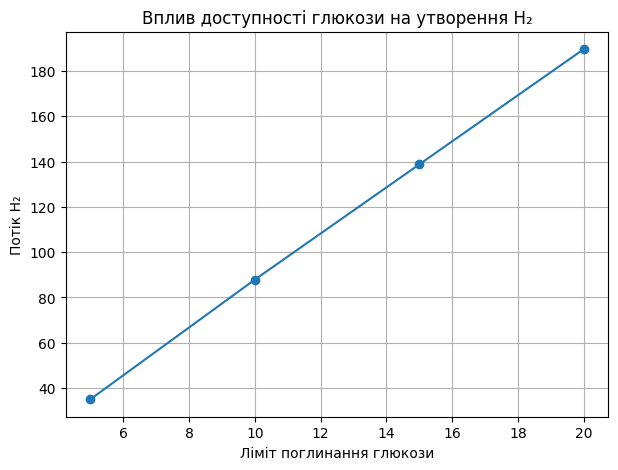

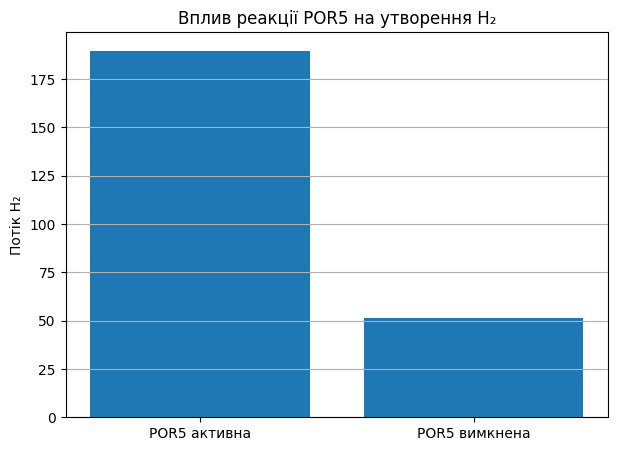

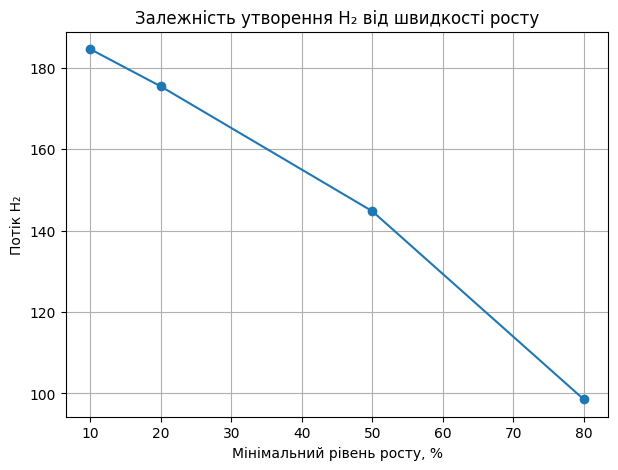

In [ ]:

import matplotlib.pyplot as plt

# 1. Вплив поглинання глюкози
plt.figure(figsize=(7, 5))
plt.plot(
    results_df["Glucose_limit"],
    results_df["H2"],
    marker="o"
)
plt.xlabel("Ліміт поглинання глюкози")
plt.ylabel("Потік H₂")
plt.title("Вплив доступності глюкози на утворення H₂")
plt.grid(True)
plt.savefig("graph_glucose.png", dpi=300, bbox_inches="tight")
plt.show()


# 2. Вплив реакції POR5
plt.figure(figsize=(7, 5))
plt.bar(
    ["POR5 активна", "POR5 вимкнена"],
    results_por_df["H2"]
)
plt.ylabel("Потік H₂")
plt.title("Вплив реакції POR5 на утворення H₂")
plt.grid(axis="y")
plt.savefig("graph_por5.png", dpi=300, bbox_inches="tight")
plt.show()


# 3. Вплив мінімального росту
plt.figure(figsize=(7, 5))
plt.plot(
    growth_df["Minimum_growth_percent"],
    growth_df["H2"],
    marker="o"
)
plt.xlabel("Мінімальний рівень росту, %")
plt.ylabel("Потік H₂")
plt.title("Залежність утворення H₂ від швидкості росту")
plt.grid(True)
plt.savefig("graph_growth.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
# Отримуємо реакцію POR5
por5 = h2_model.reactions.get_by_id("POR5")

print("Назва:", por5.name)
print("Рівняння:", por5.reaction)
print("Межі потоку:", por5.bounds)

print("\nПотік POR5 у базовому розрахунку:")
print(h2_solution.fluxes["POR5"])

print("\nПотік POR5 при loopless FBA:")
print(loop_solution.fluxes["POR5"])

print("\nГени, пов'язані з реакцією:")
print(por5.gene_reaction_rule)

Назва: Pyruvate synthase
Рівняння: coa_c + 2.0 flxso_c + pyr_c <=> accoa_c + co2_c + 2.0 flxr_c + h_c
Межі потоку: (-1000.0, 1000.0)

Потік POR5 у базовому розрахунку:
-80.1749249980504

Потік POR5 при loopless FBA:
-80.17493022333954

Гени, пов'язані з реакцією:
(b1378 and b0684) or (b1378 and b2895)


In [ ]:
# Перевіряємо потоки основних реакцій
reaction_ids = [
    "POR5",
    "FLDR2",
    "G6PDH2r",
    "GND",
    "THD2pp",
    "PFL",
    "FHL"
]

print("Метаболічні потоки:")
for rid in reaction_ids:
    print(rid, round(h2_solution.fluxes[rid], 4))


# Перевіряємо формули метаболітів
metabolite_ids = [
    "flxso_c",
    "flxr_c",
    "pyr_c",
    "accoa_c",
    "co2_c",
    "nadph_c",
    "nadp_c"
]

print("\nФормули та заряди метаболітів:")

for mid in metabolite_ids:
    met = model.metabolites.get_by_id(mid)
    print(mid, "| Формула:", met.formula,
          "| Заряд:", met.charge)

Метаболічні потоки:
POR5 -80.1749
FLDR2 80.175
G6PDH2r 36.2917
GND 36.2917
THD2pp 7.8326
PFL 87.8602
FHL 87.8602

Формули та заряди метаболітів:
flxso_c | Формула: XH | Заряд: 0
flxr_c | Формула: XH | Заряд: -1
pyr_c | Формула: C3H3O3 | Заряд: -1
accoa_c | Формула: C23H34N7O17P3S | Заряд: -4
co2_c | Формула: CO2 | Заряд: 0
nadph_c | Формула: C21H26N7O17P3 | Заряд: -4
nadp_c | Формула: C21H25N7O17P3 | Заряд: -3


In [ ]:
# Реакції, у яких бере участь флаводоксин
flxso = model.metabolites.get_by_id("flxso_c")
flxr = model.metabolites.get_by_id("flxr_c")

reactions_to_check = set(flxso.reactions) | set(flxr.reactions)

print("Реакції флаводоксину:\n")

for reaction in sorted(reactions_to_check, key=lambda r: r.id):
    flux = h2_solution.fluxes[reaction.id]

    print("Реакція:", reaction.id)
    print("Назва:", reaction.name)
    print("Рівняння:", reaction.reaction)
    print("Потік:", round(flux, 5))
    print("-" * 50)

Реакції флаводоксину:

Реакція: FLDR2
Назва: Flavodoxin reductase (NADPH)
Рівняння: 2.0 flxso_c + nadph_c --> 2.0 flxr_c + h_c + nadp_c
Потік: 80.17497
--------------------------------------------------
Реакція: MECDPDH5
Назва: 2C-methyl-D-erythritol 2,4 cyclodiphosphate dehydratase
Рівняння: 2mecdp_c + 2.0 flxr_c + h_c --> 2.0 flxso_c + h2mb4p_c + h2o_c
Потік: 5e-05
--------------------------------------------------
Реакція: POR5
Назва: Pyruvate synthase
Рівняння: coa_c + 2.0 flxso_c + pyr_c <=> accoa_c + co2_c + 2.0 flxr_c + h_c
Потік: -80.17492
--------------------------------------------------
Реакція: RNTR1c2
Назва: Ribonucleoside-triphosphate reductase (ATP) (flavodoxin)
Рівняння: atp_c + 2.0 flxr_c + 2.0 h_c --> datp_c + 2.0 flxso_c + h2o_c
Потік: 0.0
--------------------------------------------------
Реакція: RNTR2c2
Назва: Ribonucleoside-triphosphate reductase (GTP) (flavodoxin)
Рівняння: 2.0 flxr_c + gtp_c + 2.0 h_c --> dgtp_c + 2.0 flxso_c + h2o_c
Потік: 0.0
----------------

In [ ]:
conditions = {
    "Базова модель": [],
    "FLDR2 вимкнена": ["FLDR2"],
    "POR5 вимкнена": ["POR5"],
    "FLDR2 і POR5 вимкнені": ["FLDR2", "POR5"]
}

for name, reactions in conditions.items():
    test = h2_model.copy()

    for rid in reactions:
        test.reactions.get_by_id(rid).bounds = (0, 0)

    test.objective = "EX_h2_e"
    test.objective_direction = "max"

    solution = test.optimize()

    print("\n", name)
    print("Статус:", solution.status)

    if solution.status == "optimal":
        print("H2:", round(solution.fluxes["EX_h2_e"], 5))
        print("Ріст:", round(
            solution.fluxes["BIOMASS_Ec_iML1515_core_75p37M"], 5
        ))
        print("FLDR2:", round(solution.fluxes["FLDR2"], 5))
        print("POR5:", round(solution.fluxes["POR5"], 5))


 Базова модель
Статус: optimal
H2: 87.86023
Ріст: 0.01962
FLDR2: 80.17498
POR5: -80.17493

 FLDR2 вимкнена
Статус: optimal
H2: 24.89453
Ріст: 0.01962
FLDR2: 0.0
POR5: 5e-05

 POR5 вимкнена
Статус: optimal
H2: 24.89458
Ріст: 0.01962
FLDR2: 5e-05
POR5: 0.0

 FLDR2 і POR5 вимкнені
Статус: infeasible


/usr/local/lib/python3.13/dist-packages/cobra/util/solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)


In [ ]:
print("=== ПЕРЕВІРКА МОДЕЛІ ===")

print("Кількість реакцій:", len(model.reactions))
print("Кількість метаболітів:", len(model.metabolites))

print("\n=== НАЛАШТУВАННЯ h2_model ===")

for rid in ["EX_o2_e", "FHL", "PPTHpp", "EX_glc__D_e"]:
    r = h2_model.reactions.get_by_id(rid)
    print(rid, "|", r.name, "| Межі:", r.bounds)

print("\n=== БАЗОВІ РЕЗУЛЬТАТИ ===")

print("Статус:", h2_solution.status)
print("Вихід H2:", h2_solution.fluxes["EX_h2_e"])
print("Ріст:", h2_solution.fluxes["BIOMASS_Ec_iML1515_core_75p37M"])

print("PFL:", h2_solution.fluxes["PFL"])
print("FHL:", h2_solution.fluxes["FHL"])
print("POR5:", h2_solution.fluxes["POR5"])
print("FLDR2:", h2_solution.fluxes["FLDR2"])

=== ПЕРЕВІРКА МОДЕЛІ ===
Кількість реакцій: 2712
Кількість метаболітів: 1877

=== НАЛАШТУВАННЯ h2_model ===
EX_o2_e | O2 exchange | Межі: (0, 1000.0)
FHL | Formate-hydrogen lyase | Межі: (0, 1000)
PPTHpp | Phosphonate hydrogenase (periplasm) | Межі: (0, 0)
EX_glc__D_e | D-Glucose exchange | Межі: (-10.0, 1000.0)

=== БАЗОВІ РЕЗУЛЬТАТИ ===
Статус: optimal
Вихід H2: 87.86022644351455
Ріст: 0.019617163820882084
PFL: 87.86017832261173
FHL: 87.86022644351455
POR5: -80.1749249980504
FLDR2: 80.17497186345477


In [ ]:
for rid in ["PFL", "FHL", "POR5", "FLDR2"]:
    r = h2_model.reactions.get_by_id(rid)

    print("\n", rid, "-", r.name)
    print(r.reaction)


 PFL - Pyruvate formate lyase
coa_c + pyr_c --> accoa_c + for_c

 FHL - Formate-hydrogen lyase
for_c + h_c --> co2_c + h2_c

 POR5 - Pyruvate synthase
coa_c + 2.0 flxso_c + pyr_c <=> accoa_c + co2_c + 2.0 flxr_c + h_c

 FLDR2 - Flavodoxin reductase (NADPH)
2.0 flxso_c + nadph_c --> 2.0 flxr_c + h_c + nadp_c


In [ ]:
formate = h2_model.metabolites.get_by_id("for_c")

print("Реакції, пов'язані з форміатом:\n")

for reaction in sorted(formate.reactions, key=lambda r: r.id):
    flux = h2_solution.fluxes[reaction.id]

    if abs(flux) > 0.0001:
        print("Реакція:", reaction.id)
        print("Назва:", reaction.name)
        print("Рівняння:", reaction.reaction)
        print("Потік:", round(flux, 5))
        print("-" * 45)

Реакції, пов'язані з форміатом:

Реакція: FHL
Назва: Formate-hydrogen lyase
Рівняння: for_c + h_c --> co2_c + h2_c
Потік: 87.86023
---------------------------------------------
Реакція: PFL
Назва: Pyruvate formate lyase
Рівняння: coa_c + pyr_c --> accoa_c + for_c
Потік: 87.86018
---------------------------------------------


In [ ]:
pyruvate = h2_model.metabolites.get_by_id("pyr_c")

print("Реакції, пов'язані з піруватом:\n")

for reaction in sorted(pyruvate.reactions, key=lambda r: r.id):
    flux = h2_solution.fluxes[reaction.id]
    coeff = reaction.metabolites[pyruvate]
    net = coeff * flux

    if abs(net) > 0.0001:
        role = "утворення пірувату" if net > 0 else "споживання пірувату"

        print("Реакція:", reaction.id)
        print("Назва:", reaction.name)
        print("Рівняння:", reaction.reaction)
        print("Потік:", round(flux, 5))
        print("Роль:", role)
        print("Внесок у баланс:", round(net, 5))
        print("-" * 45)

Реакції, пов'язані з піруватом:

Реакція: ACHBS
Назва: 2-aceto-2-hydroxybutanoate synthase
Рівняння: 2obut_c + h_c + pyr_c --> 2ahbut_c + co2_c
Потік: 0.0057
Роль: споживання пірувату
Внесок у баланс: -0.0057
---------------------------------------------
Реакція: ACLS
Назва: Acetolactate synthase
Рівняння: h_c + 2.0 pyr_c --> alac__S_c + co2_c
Потік: 0.01715
Роль: споживання пірувату
Внесок у баланс: -0.03431
---------------------------------------------
Реакція: ANS
Назва: Anthranilate synthase
Рівняння: chor_c + gln__L_c --> anth_c + glu__L_c + h_c + pyr_c
Потік: 0.00112
Роль: утворення пірувату
Внесок у баланс: 0.00112
---------------------------------------------
Реакція: CYSTL
Назва: Cystathionine b-lyase
Рівняння: cyst__L_c + h2o_c --> hcys__L_c + nh4_c + pyr_c
Потік: 0.00302
Роль: утворення пірувату
Внесок у баланс: 0.00302
---------------------------------------------
Реакція: DHDPS
Назва: Dihydrodipicolinate synthase
Рівняння: aspsa_c + pyr_c --> 23dhdp_c + 2.0 h2o_c + h_c
Пот

In [ ]:
nadph = h2_model.metabolites.get_by_id("nadph_c")

print("Реакції, пов'язані з NADPH:\n")

for reaction in sorted(nadph.reactions, key=lambda r: r.id):
    flux = h2_solution.fluxes[reaction.id]
    coeff = reaction.metabolites[nadph]
    net = coeff * flux

    if abs(net) > 0.0001:
        role = "утворення NADPH" if net > 0 else "споживання NADPH"

        print("Реакція:", reaction.id)
        print("Назва:", reaction.name)
        print("Рівняння:", reaction.reaction)
        print("Потік:", round(flux, 5))
        print("Роль:", role)
        print("Внесок у баланс:", round(net, 5))
        print("-" * 45)

Реакції, пов'язані з NADPH:

Реакція: 3OAR140
Назва: 3-oxoacyl-[acyl-carrier-protein] reductase (n-C14:0)
Рівняння: 3omrsACP_c + h_c + nadph_c <=> 3hmrsACP_c + nadp_c
Потік: 0.00153
Роль: споживання NADPH
Внесок у баланс: -0.00153
---------------------------------------------
Реакція: AGPR
Назва: N-acetyl-g-glutamyl-phosphate reductase
Рівняння: acg5sa_c + nadp_c + pi_c <=> acg5p_c + h_c + nadph_c
Потік: -0.0058
Роль: споживання NADPH
Внесок у баланс: -0.0058
---------------------------------------------
Реакція: ASAD
Назва: Aspartate-semialdehyde dehydrogenase
Рівняння: aspsa_c + nadp_c + pi_c <=> 4pasp_c + h_c + nadph_c
Потік: -0.02097
Роль: споживання NADPH
Внесок у баланс: -0.02097
---------------------------------------------
Реакція: DHDPRy
Назва: Dihydrodipicolinate reductase (NADPH)
Рівняння: 23dhdp_c + h_c + nadph_c --> nadp_c + thdp_c
Потік: 0.00728
Роль: споживання NADPH
Внесок у баланс: -0.00728
---------------------------------------------
Реакція: DHFR
Назва: Dihydrofolat

In [ ]:
limits = [0, 5, 10, 20, 40, 80, 1000]

print("Вплив обмеження FLDR2 на утворення H2\n")

for limit in limits:
    test = h2_model.copy()

    test.reactions.get_by_id("FLDR2").upper_bound = limit

    solution = test.optimize()

    if solution.status == "optimal":
        print(
            f"FLDR2 max = {limit:4} | "
            f"H2 = {solution.fluxes['EX_h2_e']:.5f} | "
            f"POR5 = {solution.fluxes['POR5']:.5f} | "
            f"Biomass = {solution.fluxes[biomass_id]:.5f}"
        )
    else:
        print(f"FLDR2 max = {limit:4} | Статус: {solution.status}")

Вплив обмеження FLDR2 на утворення H2

FLDR2 max =    0 | H2 = 24.89453 | POR5 = 0.00005 | Biomass = 0.01962
FLDR2 max =    5 | H2 = 30.50428 | POR5 = -4.99995 | Biomass = 0.01962
FLDR2 max =   10 | H2 = 36.11404 | POR5 = -9.99995 | Biomass = 0.01962
FLDR2 max =   20 | H2 = 46.72412 | POR5 = -19.99995 | Biomass = 0.01962
FLDR2 max =   40 | H2 = 66.72412 | POR5 = -39.99995 | Biomass = 0.01962
FLDR2 max =   80 | H2 = 87.81649 | POR5 = -79.99995 | Biomass = 0.01962
FLDR2 max = 1000 | H2 = 87.86023 | POR5 = -80.17493 | Biomass = 0.01962


In [ ]:
ppp_reactions = [
    "G6PDH2r",
    "GND",
    "PGL",
    "RPI",
    "RPE",
    "TKT1",
    "TKT2",
    "TALA",
    "PFK",
    "FBP",
    "FBA"
]

print("Потоки пентозофосфатного шляху:\n")

for rid in ppp_reactions:
    reaction = h2_model.reactions.get_by_id(rid)
    flux = h2_solution.fluxes[rid]

    print(
        rid,
        "|",
        reaction.name,
        "| Потік:",
        round(flux, 5)
    )

Потоки пентозофосфатного шляху:



NameError: name 'h2_model' is not defined

In [ ]:
print("model:", "model" in globals())
print("h2_model:", "h2_model" in globals())
print("h2_solution:", "h2_solution" in globals())

model: False
h2_model: False
h2_solution: False


In [ ]:
import os

model_path = "/content/iML1515 (2).xml.gz"

print("Файл знайдено:", os.path.exists(model_path))

Файл знайдено: True


In [ ]:
import cobra

model_path = "/content/iML1515 (2).xml.gz"

model = cobra.io.read_sbml_model(model_path)

print("Модель успішно завантажена!")
print("Назва:", model.id)
print("Кількість генів:", len(model.genes))
print("Кількість реакцій:", len(model.reactions))
print("Кількість метаболітів:", len(model.metabolites))

ModuleNotFoundError: No module named 'cobra'

In [ ]:
!pip install cobra

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 32.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 102.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 106.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [cobra]


In [ ]:
import cobra

model_path = "/content/iML1515 (2).xml.gz"

model = cobra.io.read_sbml_model(model_path)

print("Модель успішно завантажена!")
print("Назва:", model.id)
print("Кількість генів:", len(model.genes))
print("Кількість реакцій:", len(model.reactions))
print("Кількість метаболітів:", len(model.metabolites))

Модель успішно завантажена!
Назва: iML1515
Кількість генів: 1516
Кількість реакцій: 2712
Кількість метаболітів: 1877


# Метаболічне моделювання продукції водню Escherichia coli

## Мета роботи
Аналіз метаболічної моделі Escherichia coli iML1515 для дослідження шляхів утворення молекулярного водню та оцінювання впливу окремих метаболічних реакцій на його продукцію.

## Використані інструменти
- Python
- Google Colab
- COBRApy
- Метаболічна модель iML1515
- Flux Balance Analysis (FBA)

## Основні етапи дослідження
1. Завантаження та перевірка метаболічної моделі.
2. Аналіз реакції форміат-гідрогенліази (FHL).
3. Моделювання утворення водню за анаеробних умов.
4. Дослідження впливу доступності глюкози.
5. Аналіз ролі окремих метаболічних шляхів і реакцій.
6. Оцінювання співвідношення між ростом біомаси та продукцією водню.

In [ ]:
solution = model.optimize()

print("Статус моделі:", solution.status)
print("Швидкість росту:", solution.objective_value)

Статус моделі: optimal
Швидкість росту: 0.87699721425716
